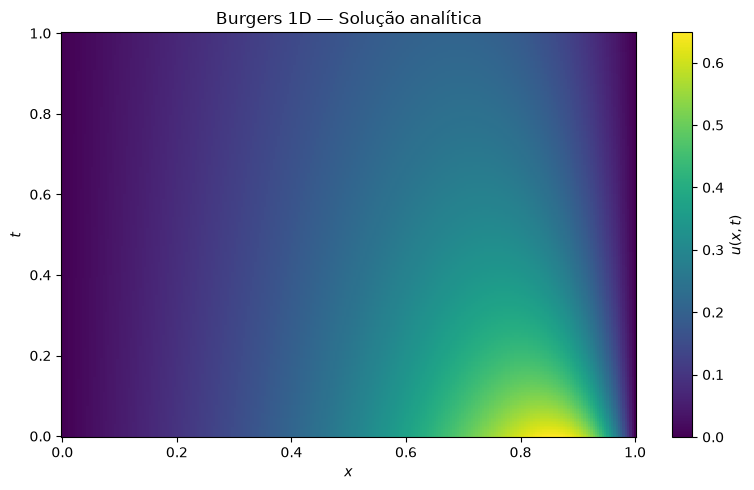

In [660]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Parâmetros do problema
nu = 0.05
a = 0.9
b = 1.0

# Solução analítica de Burgers (Cole–Hopf)
def burgers_exata(x, t):
    decay = np.exp(-nu * np.pi**2 * t)
    return (
        2 * nu * a * np.pi * decay * np.sin(np.pi * x)
        / (b + a * decay * np.cos(np.pi * x))
    )

# Domínio
x = np.linspace(0, 1, 250)
t = np.linspace(0, 1, 250)
X, T = np.meshgrid(x, t)
U = burgers_exata(X, T)

# Visualização
plt.figure(figsize=(8, 5))
plt.pcolormesh(X, T, U, shading="auto", cmap="viridis")
plt.colorbar(label=r"$u(x,t)$")
plt.xlabel(r"$x$")
plt.ylabel(r"$t$")
plt.title("Burgers 1D — Solução analítica")
plt.tight_layout()
plt.show()

In [661]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

# Caminho absoluto dos resultados no servidor
base = Path(
    "/home/camaral/inct_cq_hybrid_nn/"
    "runs/mlp_depth_2518/results/burgers"
)

profundidades = [1, 3, 5]

historicos = []
metricas = []

for depth in profundidades:
    pasta = base / f"mlp_depth_{depth}"

    # Históricos de treinamento
    arquivos = sorted(pasta.glob("seed_*/history.csv"))
    print(f"MLP-{depth}: {len(arquivos)} históricos encontrados")

    for arquivo in arquivos:
        seed = int(arquivo.parent.name.split("_")[-1])

        dados = pd.read_csv(arquivo)
        dados["depth"] = depth
        dados["seed"] = seed

        historicos.append(dados)

    # Métricas finais
    arquivos_metricas = sorted(pasta.glob("seed_*/metrics.json"))

    for arquivo in arquivos_metricas:
        seed = int(arquivo.parent.name.split("_")[-1])

        with open(arquivo) as f:
            m = json.load(f)

        m["depth"] = depth
        m["seed"] = seed

        metricas.append(m)

# Consolidar dados
df = pd.concat(historicos, ignore_index=True)
resultados = pd.DataFrame(metricas)

# Número de parâmetros de cada arquitetura
parametros = {
    1: 129,
    3: 2241,
    5: 4353
}

resultados["parameters"] = resultados["depth"].map(parametros)

print("\nHistóricos por arquitetura:")
display(df.groupby("depth")["seed"].nunique())

print("\nMétricas por arquitetura:")
display(resultados.groupby("depth")["seed"].nunique())

print("\nColunas dos históricos:")
print(df.columns.tolist())

print("\nColunas das métricas:")
print(resultados.columns.tolist())

display(resultados.head())

MLP-1: 10 históricos encontrados
MLP-3: 10 históricos encontrados
MLP-5: 10 históricos encontrados

Históricos por arquitetura:


depth
1    10
3    10
5    10
Name: seed, dtype: int64


Métricas por arquitetura:


depth
1    10
3    10
5    10
Name: seed, dtype: int64


Colunas dos históricos:
['epoch', 'train_mse', 'val_mse', 'grad_all', 'grad_aux', 'lr', 'depth', 'seed']

Colunas das métricas:
['problem', 'model', 'seed', 'device', 'parameters', 'time_s', 'best_epoch', 'best_val_mse', 'rmse', 'mae', 'relative_l2', 'max_abs_error', 'model_config', 'initial_coefficients', 'best_coefficients', 'final_coefficients', 'depth']


,problem,model,seed,device,parameters,time_s,best_epoch,best_val_mse,rmse,mae,relative_l2,max_abs_error,model_config,initial_coefficients,best_coefficients,final_coefficients,depth
0,burgers,mlp_depth_1,1924,cpu,129,18.357,5000,0.000369,0.014214,0.006570,0.064207,0.286094,"{'name': 'mlp_depth_1', 'kind': 'mlp', 'width'...",None,None,None,1
1,burgers,mlp_depth_1,1925,cpu,129,18.240,5000,0.000262,0.018099,0.008411,0.081755,0.315059,"{'name': 'mlp_depth_1', 'kind': 'mlp', 'width'...",None,None,None,1
2,burgers,mlp_depth_1,1926,cpu,129,18.124,5000,0.000352,0.016888,0.006973,0.076285,0.269709,"{'name': 'mlp_depth_1', 'kind': 'mlp', 'width'...",None,None,None,1
3,burgers,mlp_depth_1,1958,cpu,129,20.406,5000,0.000306,0.015349,0.005877,0.069332,0.303071,"{'name': 'mlp_depth_1', 'kind': 'mlp', 'width'...",None,None,None,1
4,burgers,mlp_depth_1,1962,cpu,129,19.597,5000,0.000166,0.014351,0.008655,0.064822,0.193312,"{'name': 'mlp_depth_1', 'kind': 'mlp', 'width'...",None,None,None,1


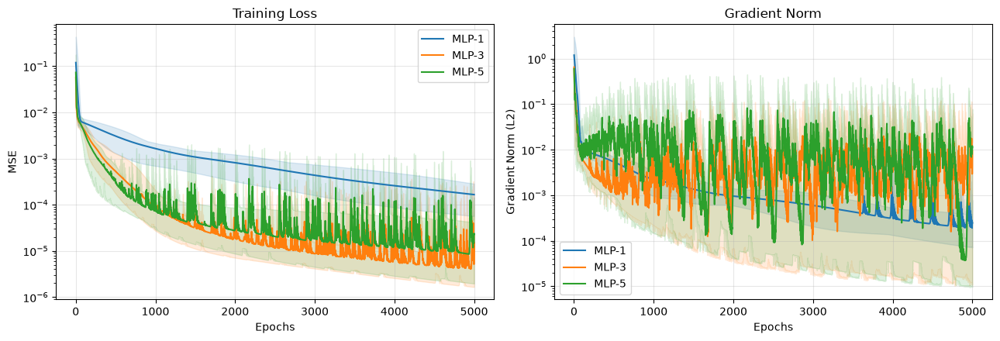

In [662]:
cores = {1: "tab:blue", 3: "tab:orange", 5: "tab:green"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for depth in profundidades:
    dados = df[df["depth"] == depth]

    for ax, coluna in [(ax1, "train_mse"), (ax2, "grad_all")]:
        resumo = dados.groupby("epoch")[coluna].agg(["mean", "min", "max"])

        ax.plot(resumo.index, resumo["mean"],
                color=cores[depth], label=f"MLP-{depth}")

        ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                        color=cores[depth], alpha=0.15)

ax1.set_title("Training Loss")
ax2.set_title("Gradient Norm")

for ax in (ax1, ax2):
    ax.set_xlabel("Epochs")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

ax1.set_ylabel("MSE")
ax2.set_ylabel("Gradient Norm (L2)")

plt.tight_layout()
plt.show()

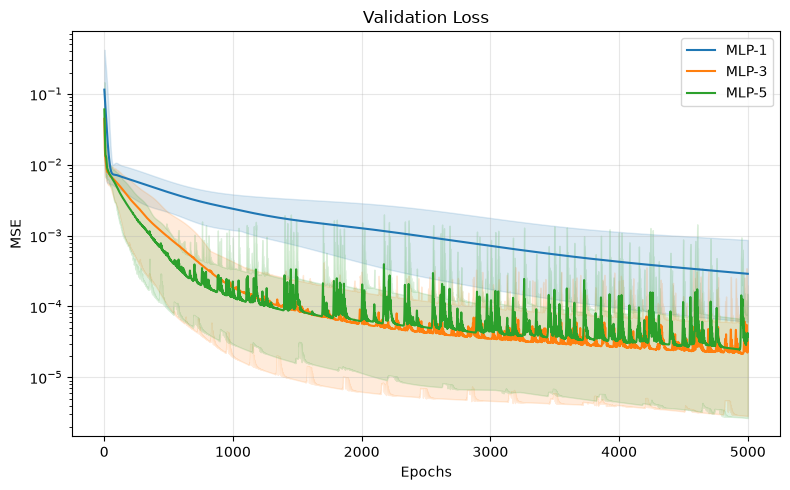

In [663]:
fig, ax = plt.subplots(figsize=(8, 5))

for depth in profundidades:
    dados = df[df["depth"] == depth]
    resumo = dados.groupby("epoch")["val_mse"].agg(["mean", "min", "max"])

    ax.plot(resumo.index, resumo["mean"],
            color=cores[depth], label=f"MLP-{depth}")

    ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                    color=cores[depth], alpha=0.15)

ax.set_title("Validation Loss")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

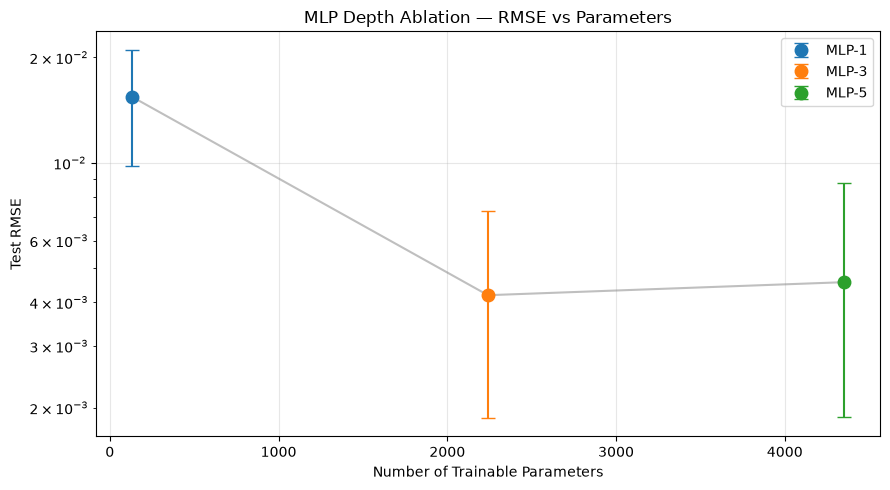

,depth,parameters,rmse_mean,rmse_min,rmse_max,rmse_std
0,1,129,0.015462,0.009817,0.021033,0.003226
1,3,2241,0.004190,0.001868,0.007266,0.001870
2,5,4353,0.004564,0.001880,0.008741,0.002099


In [664]:
resumo = (
    resultados.groupby("depth")
    .agg(
        parameters=("parameters", "first"),
        rmse_mean=("rmse", "mean"),
        rmse_min=("rmse", "min"),
        rmse_max=("rmse", "max"),
        rmse_std=("rmse", "std"),
    )
    .reset_index()
    .sort_values("parameters")
)

fig, ax = plt.subplots(figsize=(9, 5))

for _, row in resumo.iterrows():
    depth = int(row["depth"])

    ax.errorbar(
        row["parameters"],
        row["rmse_mean"],
        yerr=[
            [row["rmse_mean"] - row["rmse_min"]],
            [row["rmse_max"] - row["rmse_mean"]]
        ],
        fmt="o",
        color=cores[depth],
        markersize=9,
        capsize=5,
        label=f"MLP-{depth}"
    )

ax.plot(
    resumo["parameters"],
    resumo["rmse_mean"],
    color="gray", alpha=0.5
)

ax.set_xlabel("Number of Trainable Parameters")
ax.set_ylabel("Test RMSE")
ax.set_yscale("log")
ax.set_title("MLP Depth Ablation — RMSE vs Parameters")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

display(resumo.round(6))

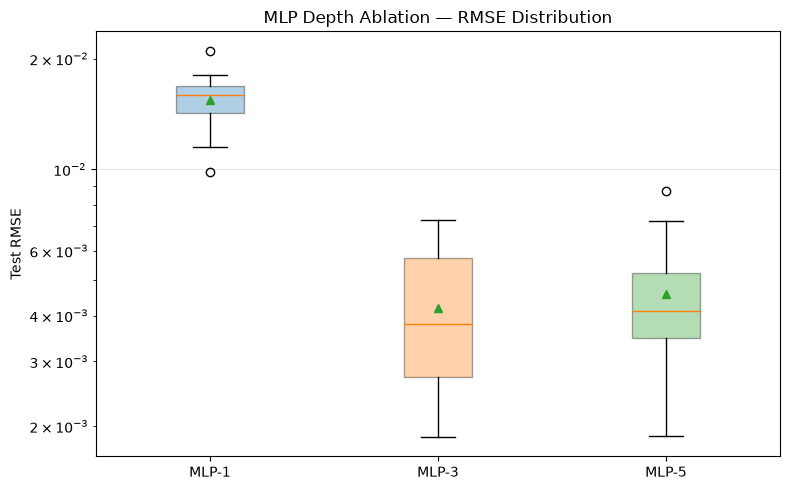

In [665]:
fig, ax = plt.subplots(figsize=(8, 5))

dados_boxplot = [
    resultados[resultados["depth"] == d]["rmse"].dropna()
    for d in profundidades
]

bp = ax.boxplot(
    dados_boxplot,
    tick_labels=[f"MLP-{d}" for d in profundidades],
    patch_artist=True,
    showmeans=True
)

for patch, d in zip(bp["boxes"], profundidades):
    patch.set_facecolor(cores[d])
    patch.set_alpha(0.35)

ax.set_ylabel("Test RMSE")
ax.set_yscale("log")
ax.set_title("MLP Depth Ablation — RMSE Distribution")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [666]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Resultados
base = Path("/home/camaral/inct_cq_hybrid_nn/runs")
pasta_depth = base / "mlp_depth_2518/results/burgers"
pasta_width = sorted(base.glob("mlp_width_*"))[-1]

historicos = []

for depth in [3, 5]:
    for width in [16, 32, 64, 128]:

        if width == 32:
            pasta = pasta_depth / f"mlp_depth_{depth}"
        else:
            pasta = pasta_width / "results" / f"mlp_d{depth}_w{width}" / "burgers" / f"mlp_d{depth}_w{width}"

        for arquivo in sorted(pasta.glob("seed_*/history.csv")):
            dados = pd.read_csv(arquivo)
            dados["depth"] = depth
            dados["width"] = width
            dados["seed"] = int(arquivo.parent.name.split("_")[-1])
            historicos.append(dados)

df = pd.concat(historicos, ignore_index=True)

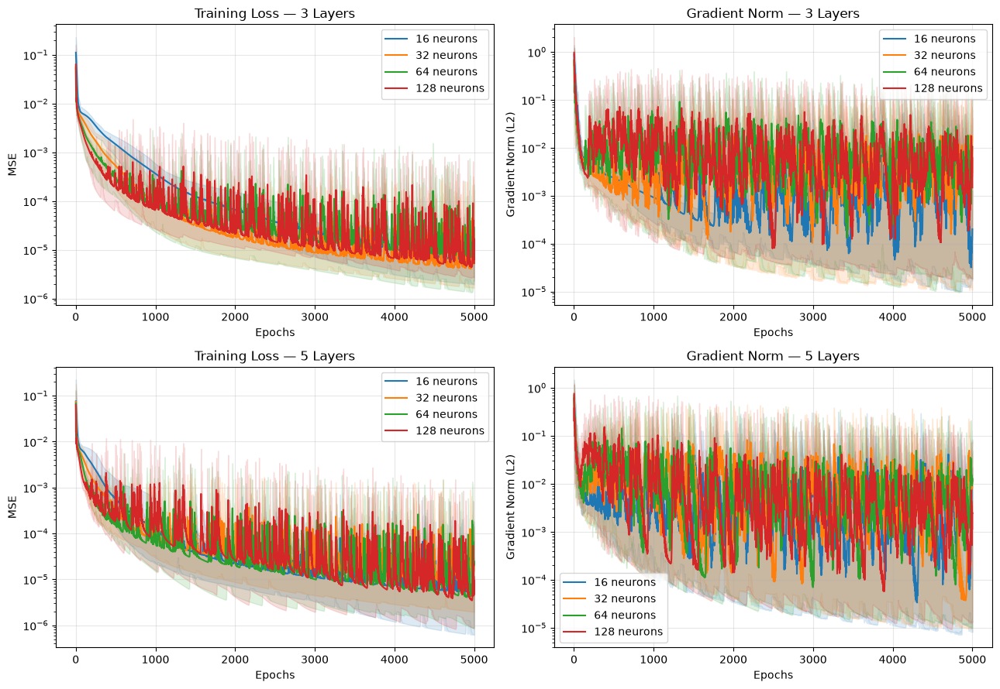

In [667]:
cores = {16: "tab:blue", 32: "tab:orange",
         64: "tab:green", 128: "tab:red"}

fig, axs = plt.subplots(2, 2, figsize=(13, 9))

for i, depth in enumerate([3, 5]):
    for width in [16, 32, 64, 128]:
        dados = df[(df["depth"] == depth) & (df["width"] == width)]

        for ax, coluna in zip(axs[i], ["train_mse", "grad_all"]):
            resumo = dados.groupby("epoch")[coluna].agg(["mean", "min", "max"])

            ax.plot(resumo.index, resumo["mean"],
                    color=cores[width], label=f"{width} neurons")

            ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                            color=cores[width], alpha=0.15)

    axs[i, 0].set_title(f"Training Loss — {depth} Layers")
    axs[i, 1].set_title(f"Gradient Norm — {depth} Layers")

for ax in axs.flat:
    ax.set_xlabel("Epochs")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

axs[0, 0].set_ylabel("MSE")
axs[1, 0].set_ylabel("MSE")
axs[0, 1].set_ylabel("Gradient Norm (L2)")
axs[1, 1].set_ylabel("Gradient Norm (L2)")

plt.tight_layout()
plt.show()

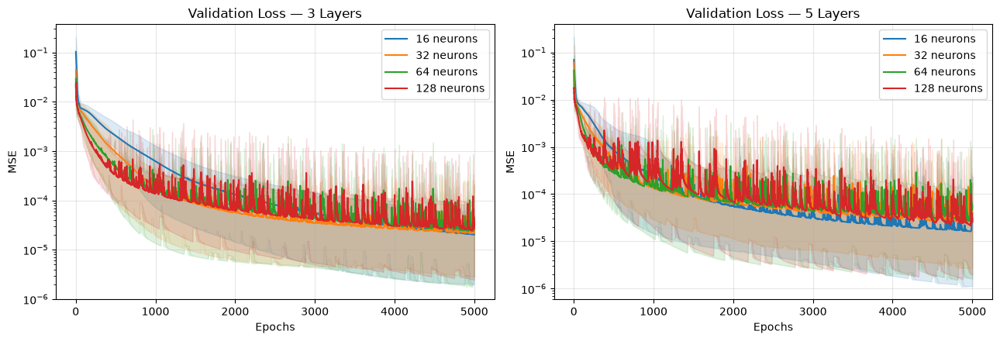

In [668]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, depth in zip(axs, [3, 5]):
    for width in [16, 32, 64, 128]:
        dados = df[(df["depth"] == depth) & (df["width"] == width)]
        resumo = dados.groupby("epoch")["val_mse"].agg(["mean", "min", "max"])

        ax.plot(resumo.index, resumo["mean"],
                color=cores[width], label=f"{width} neurons")

        ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                        color=cores[width], alpha=0.15)

    ax.set_title(f"Validation Loss — {depth} Layers")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("MSE")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [669]:
import json

metricas = []

for depth in [3, 5]:
    for width in [16, 32, 64, 128]:

        if width == 32:
            pasta = pasta_depth / f"mlp_depth_{depth}"
        else:
            nome = f"mlp_d{depth}_w{width}"
            pasta = pasta_width / "results" / nome / "burgers" / nome

        for arquivo in sorted(pasta.glob("seed_*/metrics.json")):
            with open(arquivo) as f:
                dados = json.load(f)

            dados["depth"] = depth
            dados["width"] = width
            dados["seed"] = int(arquivo.parent.name.split("_")[-1])
            dados["parameters"] = (depth - 1) * width**2 + (depth + 3) * width + 1

            metricas.append(dados)

resultados = pd.DataFrame(metricas)

display(resultados.head())

,problem,model,seed,device,parameters,time_s,best_epoch,best_val_mse,rmse,mae,relative_l2,max_abs_error,model_config,initial_coefficients,best_coefficients,final_coefficients,depth,width
0,burgers,mlp_d3_w16,1924,cpu,609,27.910,5000,0.000020,0.004065,0.001497,0.018362,0.131372,"{'name': 'mlp_d3_w16', 'kind': 'mlp', 'width':...",None,None,None,3,16
1,burgers,mlp_d3_w16,1925,cpu,609,27.619,5000,0.000018,0.005872,0.002770,0.026524,0.075883,"{'name': 'mlp_d3_w16', 'kind': 'mlp', 'width':...",None,None,None,3,16
2,burgers,mlp_d3_w16,1926,cpu,609,28.004,5000,0.000050,0.005663,0.001901,0.025579,0.123224,"{'name': 'mlp_d3_w16', 'kind': 'mlp', 'width':...",None,None,None,3,16
3,burgers,mlp_d3_w16,1958,cpu,609,28.398,4999,0.000039,0.005625,0.001537,0.025408,0.168702,"{'name': 'mlp_d3_w16', 'kind': 'mlp', 'width':...",None,None,None,3,16
4,burgers,mlp_d3_w16,1962,cpu,609,27.112,4999,0.000006,0.002510,0.001328,0.011337,0.067181,"{'name': 'mlp_d3_w16', 'kind': 'mlp', 'width':...",None,None,None,3,16


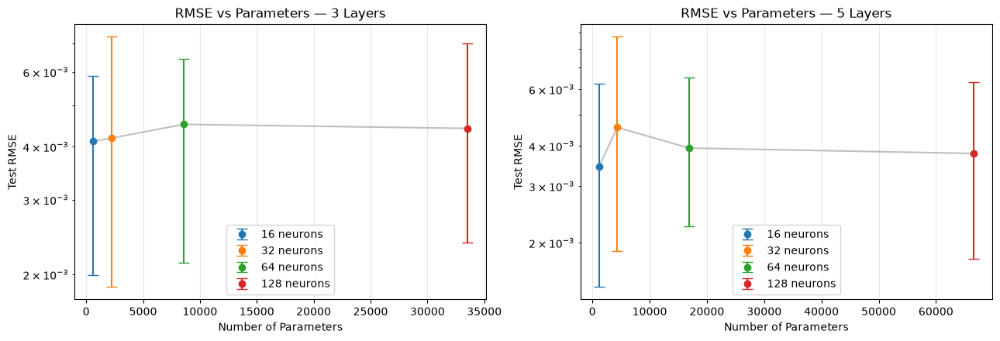

In [670]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, depth in zip(axs, [3, 5]):
    dados = resultados[resultados["depth"] == depth]

    resumo = dados.groupby("width").agg(
        parameters=("parameters", "first"),
        mean=("rmse", "mean"),
        min=("rmse", "min"),
        max=("rmse", "max")
    )

    for width, row in resumo.iterrows():
        ax.errorbar(
            row["parameters"], row["mean"],
            yerr=[[row["mean"] - row["min"]], [row["max"] - row["mean"]]],
            fmt="o", color=cores[width], capsize=5,
            label=f"{width} neurons"
        )

    ax.plot(resumo["parameters"], resumo["mean"], color="gray", alpha=0.5)
    ax.set_title(f"RMSE vs Parameters — {depth} Layers")
    ax.set_xlabel("Number of Parameters")
    ax.set_ylabel("Test RMSE")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

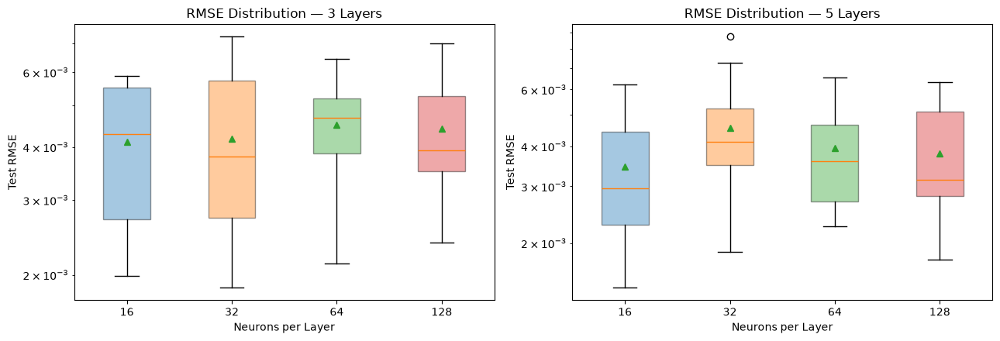

In [671]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

larguras = [16, 32, 64, 128]

for ax, depth in zip(axs, [3, 5]):
    dados = [
        resultados[(resultados["depth"] == depth) &
                   (resultados["width"] == width)]["rmse"].dropna()
        for width in larguras
    ]

    bp = ax.boxplot(
        dados,
        tick_labels=[str(w) for w in larguras],
        patch_artist=True,
        showmeans=True
    )

    for patch, width in zip(bp["boxes"], larguras):
        patch.set_facecolor(cores[width])
        patch.set_alpha(0.4)

    ax.set_title(f"RMSE Distribution — {depth} Layers")
    ax.set_xlabel("Neurons per Layer")
    ax.set_ylabel("Test RMSE")
    ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# epocas

In [672]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json

base = Path("/home/camaral/inct_cq_hybrid_nn/runs")

pasta_epochs = sorted(base.glob("mlp_epochs_[0-9]*"))[-1]
pasta_extra = sorted(base.glob("mlp_epochs_extra_*"))[-1]
pasta_depth = base / "mlp_depth_2518/results/burgers/mlp_depth_3"

epocas = [1000, 2000, 5000, 10000, 15000, 20000]
historicos = []
metricas = []

for n in epocas:
    if n == 5000:
        pasta = pasta_depth
    elif n in [15000, 20000]:
        pasta = pasta_extra / "results/burgers" / f"mlp_epochs_{n}"
    else:
        pasta = pasta_epochs / "results/burgers" / f"mlp_epochs_{n}"

    for arquivo in sorted(pasta.glob("seed_*/history.csv")):
        if arquivo.stat().st_size == 0:
            continue

        dados = pd.read_csv(arquivo)
        dados["epochs"] = n
        dados["seed"] = int(arquivo.parent.name.split("_")[-1])
        historicos.append(dados)

    for arquivo in sorted(pasta.glob("seed_*/metrics.json")):
        with open(arquivo) as f:
            dados = json.load(f)

        dados["epochs"] = n
        dados["seed"] = int(arquivo.parent.name.split("_")[-1])
        metricas.append(dados)

df = pd.concat(historicos, ignore_index=True)
resultados = pd.DataFrame(metricas)

cores = {
    1000: "tab:blue",
    2000: "tab:orange",
    5000: "tab:green",
    10000: "tab:red",
    15000: "tab:purple",
    20000: "tab:brown"
}

print(df.groupby("epochs")["seed"].nunique())

epochs
1000     10
2000     10
5000     10
10000    10
15000    10
20000    10
Name: seed, dtype: int64


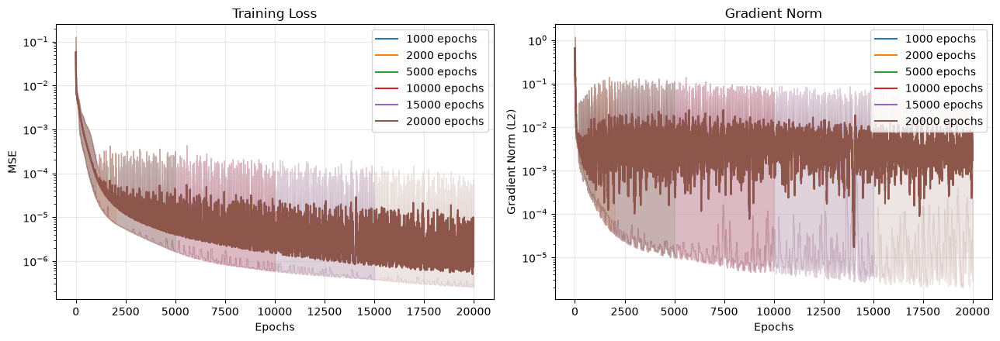

In [673]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for n in epocas:
    dados = df[df["epochs"] == n]

    if dados.empty:
        continue

    for ax, coluna in [(ax1, "train_mse"), (ax2, "grad_all")]:
        resumo = dados.groupby("epoch")[coluna].agg(["mean", "min", "max"])

        ax.plot(resumo.index, resumo["mean"],
                color=cores[n], label=f"{n} epochs")

        ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                        color=cores[n], alpha=0.15)

ax1.set_title("Training Loss")
ax2.set_title("Gradient Norm")

for ax in (ax1, ax2):
    ax.set_xlabel("Epochs")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

ax1.set_ylabel("MSE")
ax2.set_ylabel("Gradient Norm (L2)")

plt.tight_layout()
plt.show()

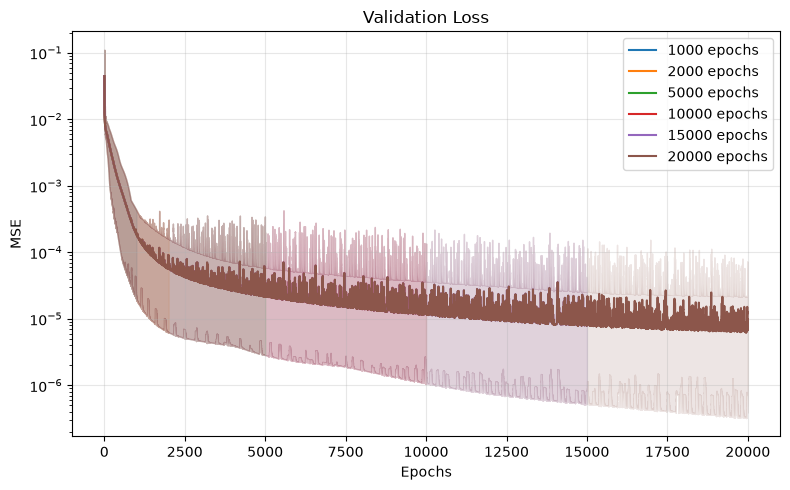

In [674]:
fig, ax = plt.subplots(figsize=(8, 5))

for n in epocas:
    dados = df[df["epochs"] == n]

    if dados.empty:
        continue

    resumo = dados.groupby("epoch")["val_mse"].agg(["mean", "min", "max"])

    ax.plot(resumo.index, resumo["mean"],
            color=cores[n], label=f"{n} epochs")

    ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                    color=cores[n], alpha=0.15)

ax.set_title("Validation Loss")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

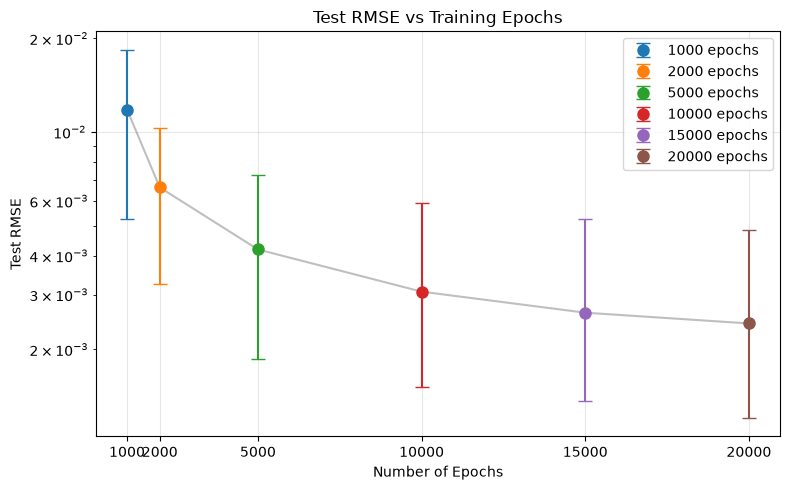

,mean,min,max
epochs,,,
1000,0.011804,0.005263,0.018376
2000,0.006631,0.003236,0.010315
5000,0.004190,0.001868,0.007266
10000,0.003066,0.001509,0.005888
15000,0.002623,0.001361,0.005266
20000,0.002423,0.001202,0.004842


In [675]:
resumo = resultados.groupby("epochs")["rmse"].agg(["mean", "min", "max"])

fig, ax = plt.subplots(figsize=(8, 5))

for n, r in resumo.iterrows():
    ax.errorbar(
        n, r["mean"],
        yerr=[[r["mean"] - r["min"]], [r["max"] - r["mean"]]],
        fmt="o", color=cores[n], capsize=5,
        markersize=8, label=f"{n} epochs"
    )

ax.plot(resumo.index, resumo["mean"], color="gray", alpha=0.5)

ax.set_title("Test RMSE vs Training Epochs")
ax.set_xlabel("Number of Epochs")
ax.set_ylabel("Test RMSE")
ax.set_xticks(epocas)
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

display(resumo.round(6))

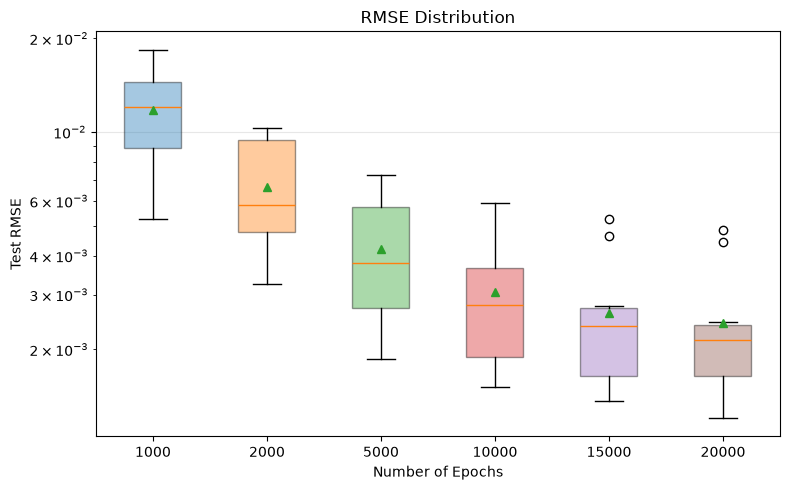

In [676]:
fig, ax = plt.subplots(figsize=(8, 5))

dados = [
    resultados[resultados["epochs"] == n]["rmse"].dropna()
    for n in epocas
]

bp = ax.boxplot(
    dados,
    tick_labels=[str(n) for n in epocas],
    patch_artist=True,
    showmeans=True
)

for patch, n in zip(bp["boxes"], epocas):
    patch.set_facecolor(cores[n])
    patch.set_alpha(0.4)

ax.set_title("RMSE Distribution")
ax.set_xlabel("Number of Epochs")
ax.set_ylabel("Test RMSE")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [677]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json

base = Path("/home/camaral/inct_cq_hybrid_nn/runs")

# Experimentos de learning rate
pasta_lr = sorted(base.glob("mlp_lr_[0-9]*"))[-1]

# Experimento de referência: 15.000 épocas, LR = 0.001
pasta_epochs = sorted(base.glob("mlp_epochs_extra_[0-9]*"))[-1]

learning_rates = [0.0001, 0.0005, 0.001, 0.005, 0.01]

historicos = []
metricas = []

for lr in learning_rates:

    if lr == 0.001:
        pasta = pasta_epochs / "results/burgers/mlp_epochs_15000"
    else:
        nome = f"mlp_lr_{str(lr).replace('.', 'p')}"
        pasta = pasta_lr / "results/burgers" / nome

    for arquivo in sorted(pasta.glob("seed_*/history.csv")):
        if arquivo.stat().st_size == 0:
            continue

        dados = pd.read_csv(arquivo)

        # Apenas históricos com até 15.000 épocas
        dados = dados[dados["epoch"] <= 15000]

        dados["learning_rate"] = lr
        dados["seed"] = int(arquivo.parent.name.split("_")[-1])
        historicos.append(dados)

    for arquivo in sorted(pasta.glob("seed_*/metrics.json")):
        with open(arquivo) as f:
            dados = json.load(f)

        dados["learning_rate"] = lr
        dados["seed"] = int(arquivo.parent.name.split("_")[-1])
        metricas.append(dados)

df = pd.concat(historicos, ignore_index=True)
resultados = pd.DataFrame(metricas)

cores = {
    0.0001: "tab:blue",
    0.0005: "tab:orange",
    0.001: "tab:green",
    0.005: "tab:red",
    0.01: "tab:purple"
}

print(df.groupby("learning_rate").agg(
    sementes=("seed", "nunique"),
    epoca_maxima=("epoch", "max")
))

               sementes  epoca_maxima
learning_rate                        
0.0001               10         15000
0.0005               10         15000
0.0010               10         15000
0.0050               10         15000
0.0100               10         15000


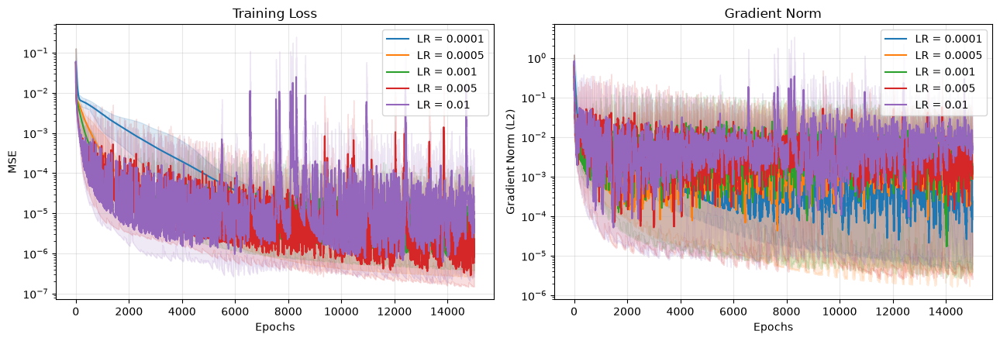

In [678]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for lr in learning_rates:
    dados = df[df["learning_rate"] == lr]

    for ax, coluna in [(ax1, "train_mse"), (ax2, "grad_all")]:
        resumo = dados.groupby("epoch")[coluna].agg(["mean", "min", "max"])

        ax.plot(resumo.index, resumo["mean"],
                color=cores[lr], label=f"LR = {lr:g}")

        ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                        color=cores[lr], alpha=0.15)

ax1.set_title("Training Loss")
ax2.set_title("Gradient Norm")

for ax in (ax1, ax2):
    ax.set_xlabel("Epochs")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

ax1.set_ylabel("MSE")
ax2.set_ylabel("Gradient Norm (L2)")

plt.tight_layout()
plt.show()

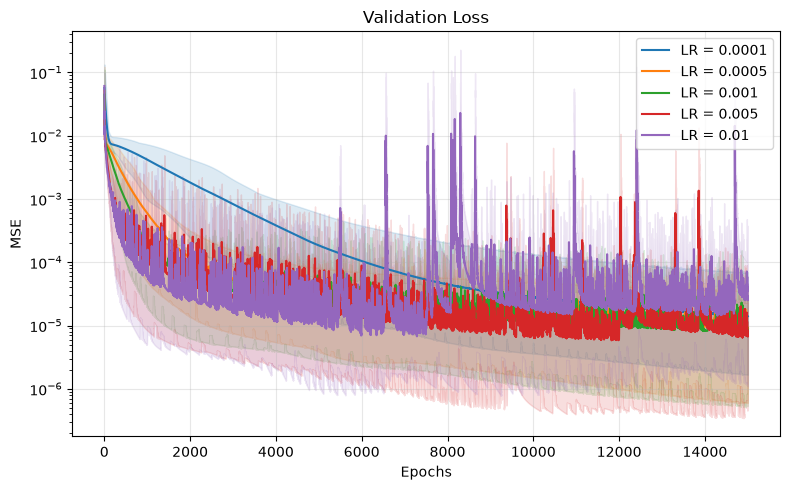

In [679]:
fig, ax = plt.subplots(figsize=(8, 5))

for lr in learning_rates:
    dados = df[df["learning_rate"] == lr]
    resumo = dados.groupby("epoch")["val_mse"].agg(["mean", "min", "max"])

    ax.plot(resumo.index, resumo["mean"],
            color=cores[lr], label=f"LR = {lr:g}")

    ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                    color=cores[lr], alpha=0.15)

ax.set_title("Validation Loss")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

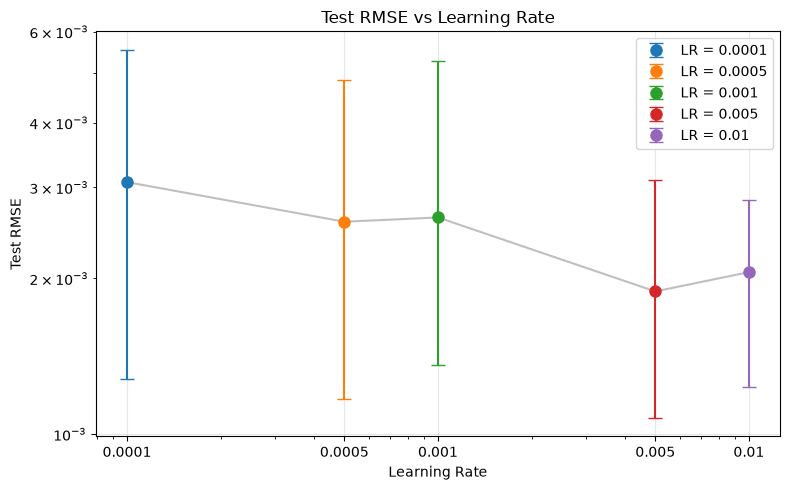

,mean,min,max
learning_rate,,,
0.0001,0.003070,0.001280,0.005535
0.0005,0.002574,0.001169,0.004841
0.0010,0.002623,0.001361,0.005266
0.0050,0.001887,0.001074,0.003095
0.0100,0.002056,0.001235,0.002841


In [680]:
resumo = resultados.groupby("learning_rate")["rmse"].agg(["mean", "min", "max"])

fig, ax = plt.subplots(figsize=(8, 5))

for lr, r in resumo.iterrows():
    ax.errorbar(
        lr, r["mean"],
        yerr=[[r["mean"] - r["min"]], [r["max"] - r["mean"]]],
        fmt="o", color=cores[lr], capsize=5,
        markersize=8, label=f"LR = {lr:g}"
    )

ax.plot(resumo.index, resumo["mean"], color="gray", alpha=0.5)

ax.set_title("Test RMSE vs Learning Rate")
ax.set_xlabel("Learning Rate")
ax.set_ylabel("Test RMSE")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(learning_rates)
ax.set_xticklabels([f"{lr:g}" for lr in learning_rates])
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

display(resumo.round(6))

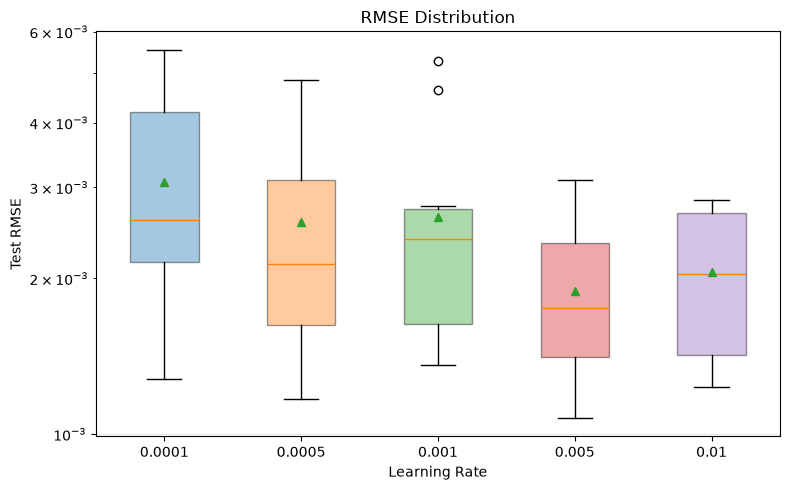

In [681]:
dados = [
    resultados[resultados["learning_rate"] == lr]["rmse"].dropna()
    for lr in learning_rates
]

fig, ax = plt.subplots(figsize=(8, 5))

bp = ax.boxplot(
    dados,
    tick_labels=[f"{lr:g}" for lr in learning_rates],
    patch_artist=True,
    showmeans=True
)

for patch, lr in zip(bp["boxes"], learning_rates):
    patch.set_facecolor(cores[lr])
    patch.set_alpha(0.4)

ax.set_title("RMSE Distribution")
ax.set_xlabel("Learning Rate")
ax.set_ylabel("Test RMSE")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [682]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json

base = Path("/home/camaral/inct_cq_hybrid_nn/runs")

pasta_lr = sorted(base.glob("mlp_lr_[0-9]*"))[-1]
pasta_cosine = sorted(base.glob("mlp_cosine_[0-9]*"))[-1]

pastas = {
    "None": pasta_lr / "results/burgers/mlp_lr_0p005",
    "Cosine": pasta_cosine / "results/burgers/mlp_cosine"
}

historicos = []
metricas = []

for scheduler, pasta in pastas.items():

    for arquivo in sorted(pasta.glob("seed_*/history.csv")):
        if arquivo.stat().st_size == 0:
            continue

        dados = pd.read_csv(arquivo)
        dados["scheduler"] = scheduler
        dados["seed"] = int(arquivo.parent.name.split("_")[-1])
        historicos.append(dados)

    for arquivo in sorted(pasta.glob("seed_*/metrics.json")):
        with open(arquivo) as f:
            dados = json.load(f)

        dados["scheduler"] = scheduler
        dados["seed"] = int(arquivo.parent.name.split("_")[-1])
        metricas.append(dados)

df = pd.concat(historicos, ignore_index=True)
resultados = pd.DataFrame(metricas)

cores = {"None": "tab:blue", "Cosine": "tab:orange"}

print(df.groupby("scheduler")["seed"].nunique())

scheduler
Cosine    10
None      10
Name: seed, dtype: int64


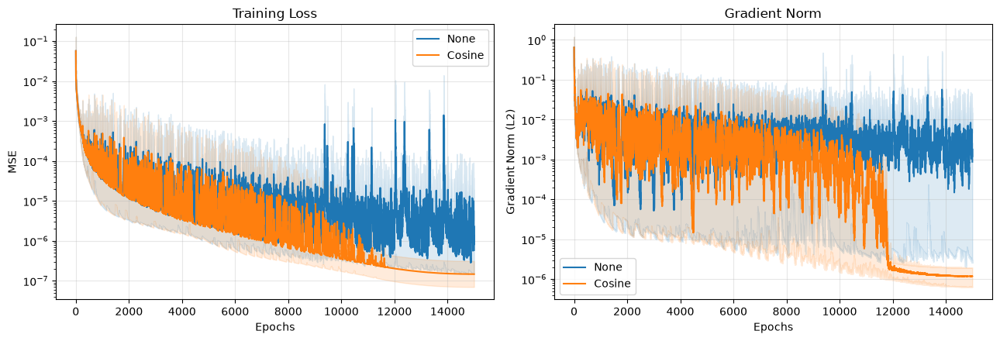

In [683]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for scheduler in pastas:
    dados = df[df["scheduler"] == scheduler]

    for ax, coluna in [(ax1, "train_mse"), (ax2, "grad_all")]:
        resumo = dados.groupby("epoch")[coluna].agg(["mean", "min", "max"])

        ax.plot(resumo.index, resumo["mean"],
                color=cores[scheduler], label=scheduler)

        ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                        color=cores[scheduler], alpha=0.15)

ax1.set_title("Training Loss")
ax2.set_title("Gradient Norm")

for ax in (ax1, ax2):
    ax.set_xlabel("Epochs")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

ax1.set_ylabel("MSE")
ax2.set_ylabel("Gradient Norm (L2)")

plt.tight_layout()
plt.show()

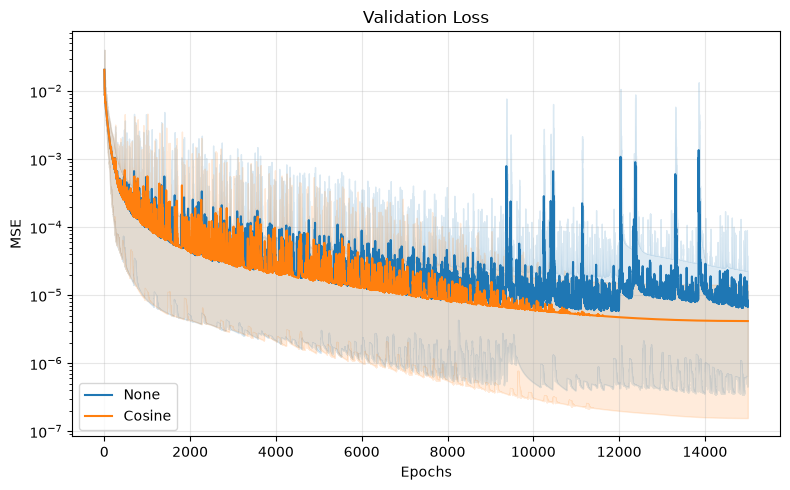

In [684]:
fig, ax = plt.subplots(figsize=(8, 5))

for scheduler in pastas:
    dados = df[df["scheduler"] == scheduler]
    resumo = dados.groupby("epoch")["val_mse"].agg(["mean", "min", "max"])

    ax.plot(resumo.index, resumo["mean"],
            color=cores[scheduler], label=scheduler)

    ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                    color=cores[scheduler], alpha=0.15)

ax.set_title("Validation Loss")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

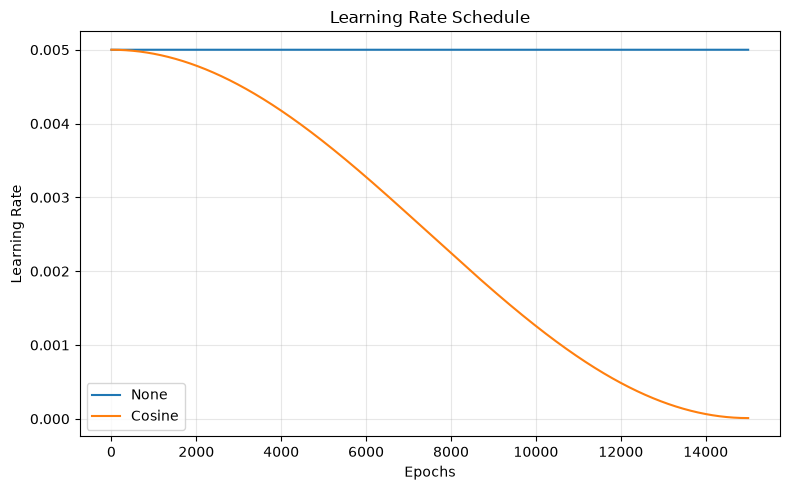

In [685]:
fig, ax = plt.subplots(figsize=(8, 5))

for scheduler in pastas:
    dados = df[df["scheduler"] == scheduler]
    resumo = dados.groupby("epoch")["lr"].mean()

    ax.plot(resumo.index, resumo,
            color=cores[scheduler], label=scheduler)

ax.set_title("Learning Rate Schedule")
ax.set_xlabel("Epochs")
ax.set_ylabel("Learning Rate")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

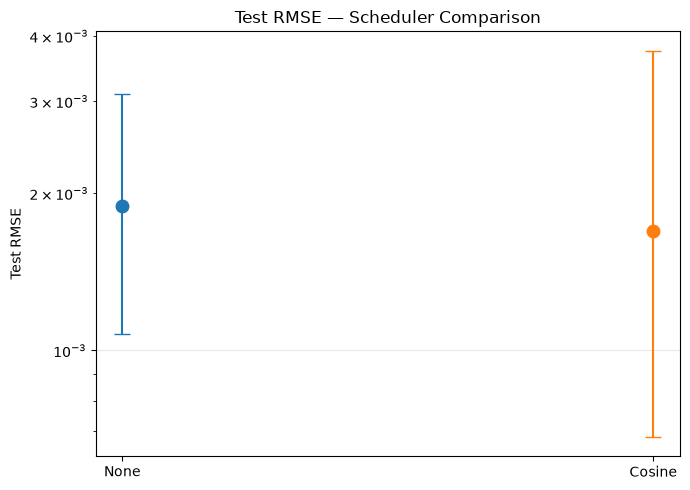

,mean,min,max,std
scheduler,,,,
Cosine,0.001694,0.000684,0.003750,0.000962
None,0.001887,0.001074,0.003095,0.000676


In [686]:
resumo = resultados.groupby("scheduler")["rmse"].agg(
    ["mean", "min", "max", "std"]
)

fig, ax = plt.subplots(figsize=(7, 5))

for i, scheduler in enumerate(pastas):
    r = resumo.loc[scheduler]

    ax.errorbar(
        i, r["mean"],
        yerr=[[r["mean"] - r["min"]], [r["max"] - r["mean"]]],
        fmt="o", color=cores[scheduler],
        capsize=6, markersize=9
    )

ax.set_xticks(range(len(pastas)))
ax.set_xticklabels(list(pastas))
ax.set_ylabel("Test RMSE")
ax.set_yscale("log")
ax.set_title("Test RMSE — Scheduler Comparison")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

display(resumo.round(6))

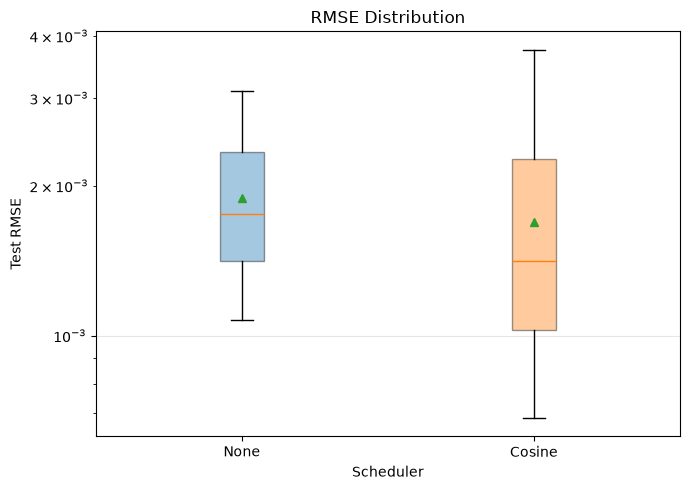

In [687]:
fig, ax = plt.subplots(figsize=(7, 5))

dados = [
    resultados[resultados["scheduler"] == scheduler]["rmse"].dropna()
    for scheduler in pastas
]

bp = ax.boxplot(
    dados,
    tick_labels=list(pastas),
    patch_artist=True,
    showmeans=True
)

for patch, scheduler in zip(bp["boxes"], pastas):
    patch.set_facecolor(cores[scheduler])
    patch.set_alpha(0.4)

ax.set_title("RMSE Distribution")
ax.set_xlabel("Scheduler")
ax.set_ylabel("Test RMSE")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [688]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json

base = Path("/home/camaral/inct_cq_hybrid_nn/runs")

pasta_points = sorted(base.glob("mlp_points_[0-9]*"))[-1]
pasta_cosine = sorted(base.glob("mlp_cosine_[0-9]*"))[-1]

pontos = [100, 300, 500, 1000, 2000]
historicos = []
metricas = []

for n in pontos:
    if n == 300:
        pasta = pasta_cosine / "results/burgers/mlp_cosine"
    else:
        pasta = pasta_points / "results/burgers" / f"mlp_points_{n}"

    for arquivo in sorted(pasta.glob("seed_*/history.csv")):
        if arquivo.stat().st_size == 0:
            continue

        dados = pd.read_csv(arquivo)
        dados["points"] = n
        dados["seed"] = int(arquivo.parent.name.split("_")[-1])
        historicos.append(dados)

    for arquivo in sorted(pasta.glob("seed_*/metrics.json")):
        with open(arquivo) as f:
            dados = json.load(f)

        dados["points"] = n
        dados["seed"] = int(arquivo.parent.name.split("_")[-1])
        metricas.append(dados)

df = pd.concat(historicos, ignore_index=True)
resultados = pd.DataFrame(metricas)

cores = {
    100: "tab:blue",
    300: "tab:orange",
    500: "tab:green",
    1000: "tab:red",
    2000: "tab:purple"
}

print("Históricos por quantidade de pontos:")
print(df.groupby("points")["seed"].nunique())

print("\nMétricas finais:")
if not resultados.empty:
    print(resultados.groupby("points")["seed"].nunique())

Históricos por quantidade de pontos:
points
100     10
300     10
500     10
1000    10
2000    10
Name: seed, dtype: int64

Métricas finais:
points
100     10
300     10
500     10
1000    10
2000    10
Name: seed, dtype: int64


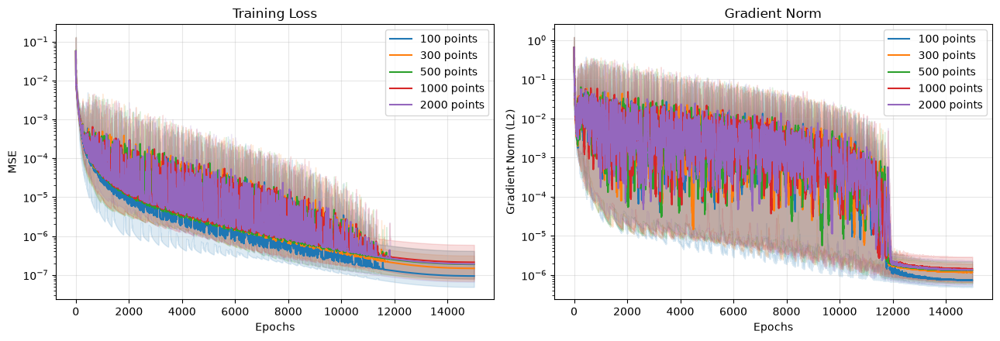

In [689]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for n in pontos:
    dados = df[df["points"] == n]

    if dados.empty:
        continue

    for ax, coluna in [(ax1, "train_mse"), (ax2, "grad_all")]:
        resumo = dados.groupby("epoch")[coluna].agg(["mean", "min", "max"])

        ax.plot(resumo.index, resumo["mean"],
                color=cores[n], label=f"{n} points")

        ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                        color=cores[n], alpha=0.15)

ax1.set_title("Training Loss")
ax2.set_title("Gradient Norm")

for ax in (ax1, ax2):
    ax.set_xlabel("Epochs")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

ax1.set_ylabel("MSE")
ax2.set_ylabel("Gradient Norm (L2)")

plt.tight_layout()
plt.show()

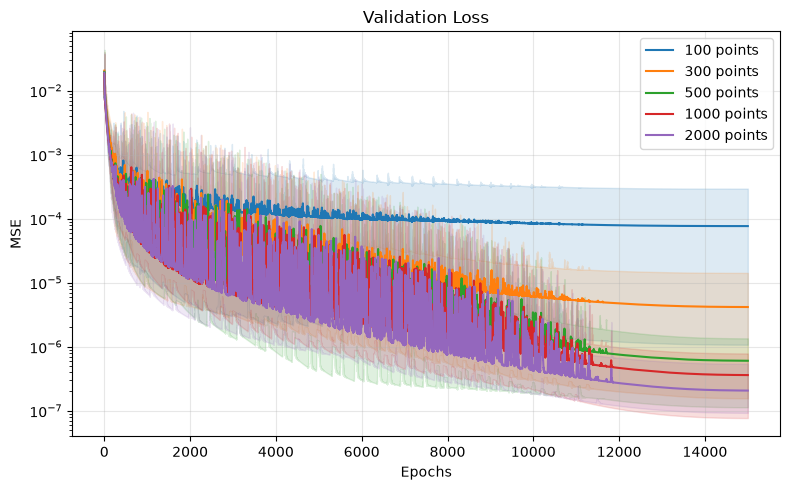

In [690]:
fig, ax = plt.subplots(figsize=(8, 5))

for n in pontos:
    dados = df[df["points"] == n]

    if dados.empty:
        continue

    resumo = dados.groupby("epoch")["val_mse"].agg(["mean", "min", "max"])

    ax.plot(resumo.index, resumo["mean"],
            color=cores[n], label=f"{n} points")

    ax.fill_between(resumo.index, resumo["min"], resumo["max"],
                    color=cores[n], alpha=0.15)

ax.set_title("Validation Loss")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

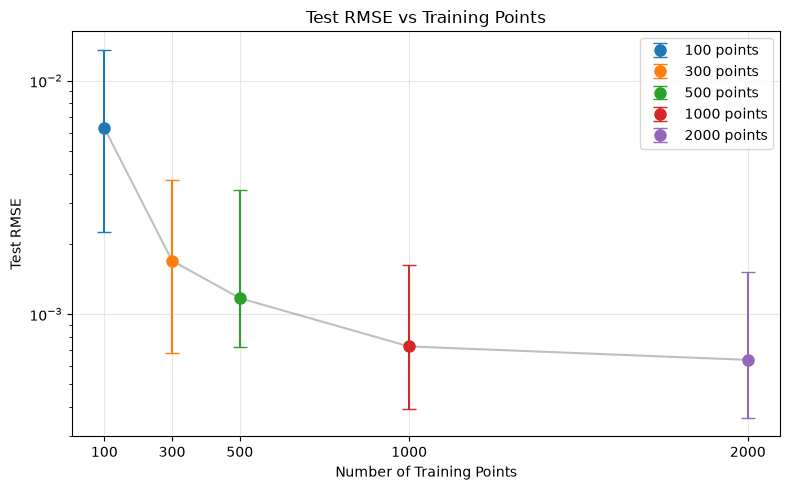

,mean,min,max,std
points,,,,
100,0.006274,0.002249,0.013585,0.004260
300,0.001694,0.000684,0.003750,0.000962
500,0.001170,0.000724,0.003399,0.000807
1000,0.000727,0.000390,0.001630,0.000353
2000,0.000637,0.000358,0.001509,0.000327


In [691]:
resumo = resultados.groupby("points")["rmse"].agg(
    ["mean", "min", "max", "std"]
)

fig, ax = plt.subplots(figsize=(8, 5))

for n, r in resumo.iterrows():
    ax.errorbar(
        n, r["mean"],
        yerr=[[r["mean"] - r["min"]], [r["max"] - r["mean"]]],
        fmt="o", color=cores[n],
        markersize=8, capsize=5,
        label=f"{n} points"
    )

ax.plot(resumo.index, resumo["mean"], color="gray", alpha=0.5)

ax.set_title("Test RMSE vs Training Points")
ax.set_xlabel("Number of Training Points")
ax.set_ylabel("Test RMSE")
ax.set_xticks(pontos)
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

display(resumo.round(6))

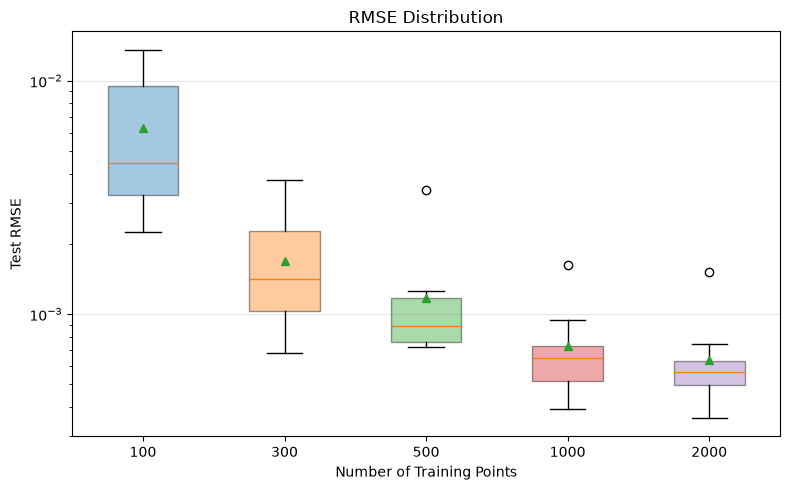

In [692]:
fig, ax = plt.subplots(figsize=(8, 5))

dados = [
    resultados[resultados["points"] == n]["rmse"].dropna()
    for n in pontos
]

bp = ax.boxplot(
    dados,
    tick_labels=[str(n) for n in pontos],
    patch_artist=True,
    showmeans=True
)

for patch, n in zip(bp["boxes"], pontos):
    patch.set_facecolor(cores[n])
    patch.set_alpha(0.4)

ax.set_title("RMSE Distribution")
ax.set_xlabel("Number of Training Points")
ax.set_ylabel("Test RMSE")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [693]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json

base = Path("/home/camaral/inct_cq_hybrid_nn/runs")
pasta_job = sorted(base.glob("mpc_quantum_[0-9]*"))[-1]

qubits_lista = [3, 5, 7]
camadas = [1, 3, 5]

historicos = []
metricas = []

for q in qubits_lista:
    for l in camadas:
        nome = f"mpc_q{q}_l{l}"
        pasta = pasta_job / "results/burgers" / nome

        for arquivo in sorted(pasta.glob("seed_*/history.csv")):
            if arquivo.stat().st_size == 0:
                continue

            dados = pd.read_csv(arquivo)
            dados["qubits"] = q
            dados["layers"] = l
            dados["seed"] = int(arquivo.parent.name.split("_")[-1])
            historicos.append(dados)

        for arquivo in sorted(pasta.glob("seed_*/metrics.json")):
            with open(arquivo) as f:
                dados = json.load(f)

            dados["qubits"] = q
            dados["layers"] = l
            dados["seed"] = int(arquivo.parent.name.split("_")[-1])
            metricas.append(dados)

df = pd.concat(historicos, ignore_index=True)
resultados = pd.DataFrame(metricas)

cores = {
    3: "tab:blue",
    5: "tab:orange",
    7: "tab:green"
}

print(df.groupby(["layers", "qubits"])["seed"].nunique())

layers  qubits
1       3         10
        5         10
        7         10
3       3         10
        5         10
        7         10
5       3         10
        5         10
        7         10
Name: seed, dtype: int64


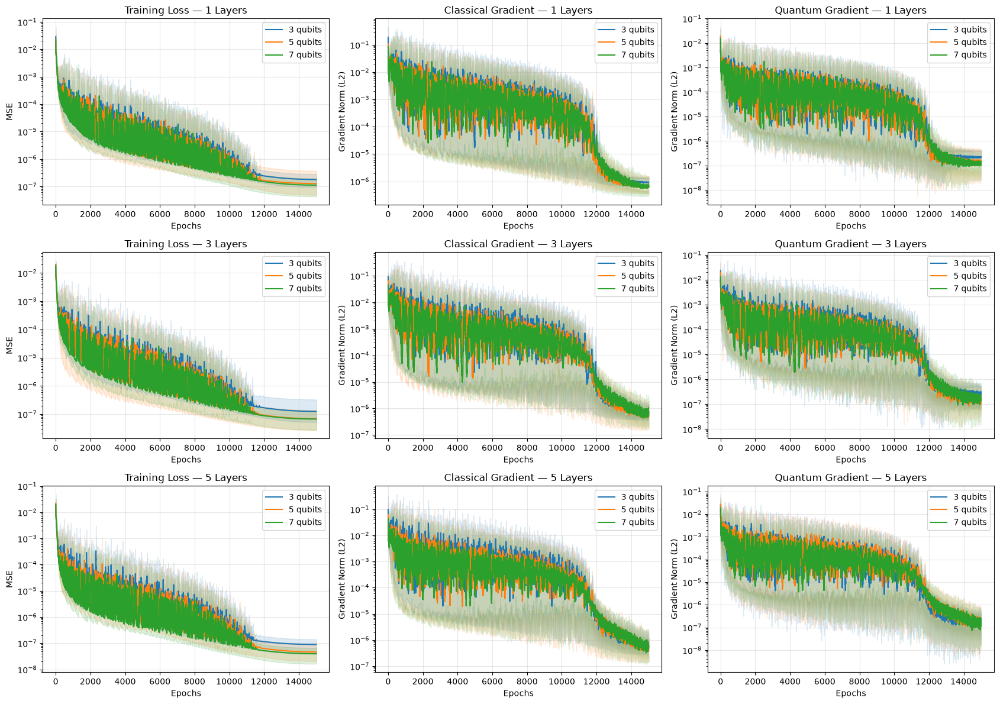

In [694]:
import numpy as np

fig, axs = plt.subplots(3, 3, figsize=(17, 12))

colunas = ["train_mse", "grad_classical", "grad_quantum"]
titulos = ["Training Loss", "Classical Gradient", "Quantum Gradient"]

for i, l in enumerate(camadas):
    for q in qubits_lista:
        dados = df[(df["layers"] == l) & (df["qubits"] == q)]

        if dados.empty:
            continue

        for j, coluna in enumerate(colunas):
            resumo = dados.groupby("epoch")[coluna].agg(["mean", "min", "max"])

            ax = axs[i, j]

            ax.plot(
                resumo.index,
                resumo["mean"].clip(lower=1e-12),
                color=cores[q],
                label=f"{q} qubits"
            )

            ax.fill_between(
                resumo.index,
                resumo["min"].clip(lower=1e-12),
                resumo["max"].clip(lower=1e-12),
                color=cores[q],
                alpha=0.15
            )

    for j, titulo in enumerate(titulos):
        axs[i, j].set_title(f"{titulo} — {l} Layers")

for ax in axs.flat:
    ax.set_xlabel("Epochs")
    ax.grid(alpha=0.3)

    # Escala log somente quando existem dados
    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

for i in range(3):
    axs[i, 0].set_ylabel("MSE")
    axs[i, 1].set_ylabel("Gradient Norm (L2)")
    axs[i, 2].set_ylabel("Gradient Norm (L2)")

plt.tight_layout()
plt.show()

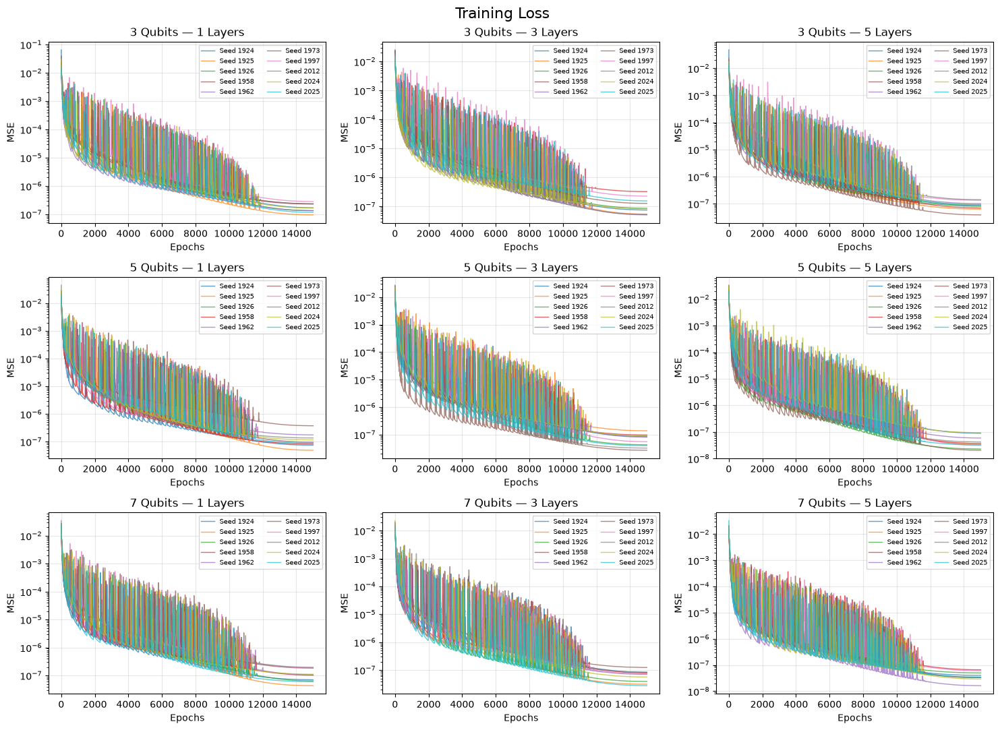

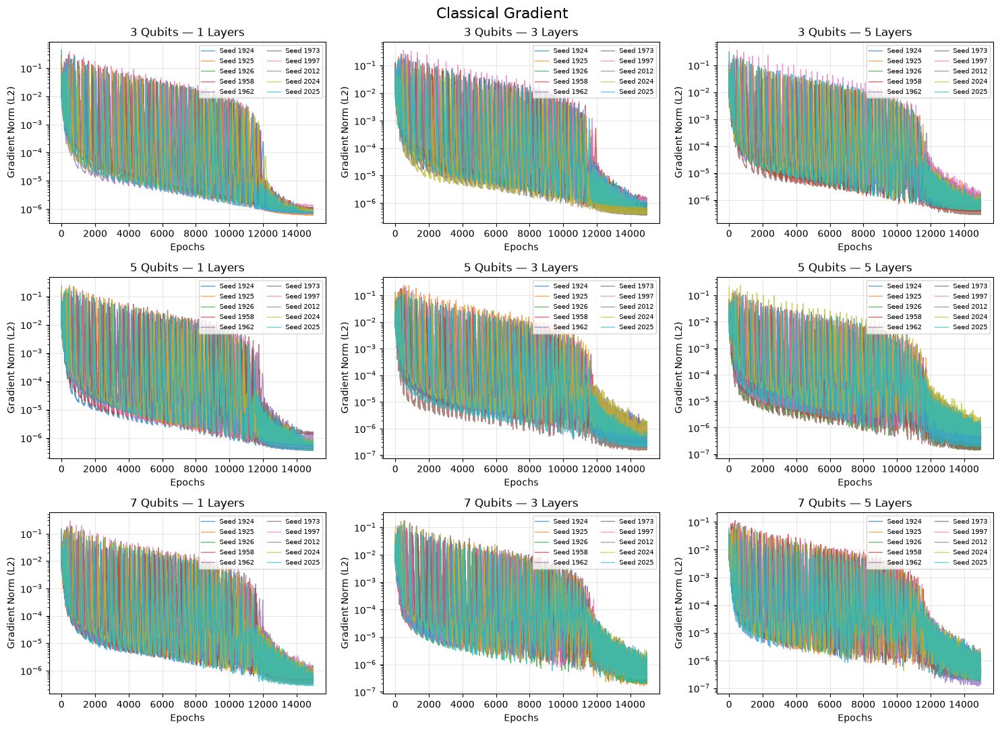

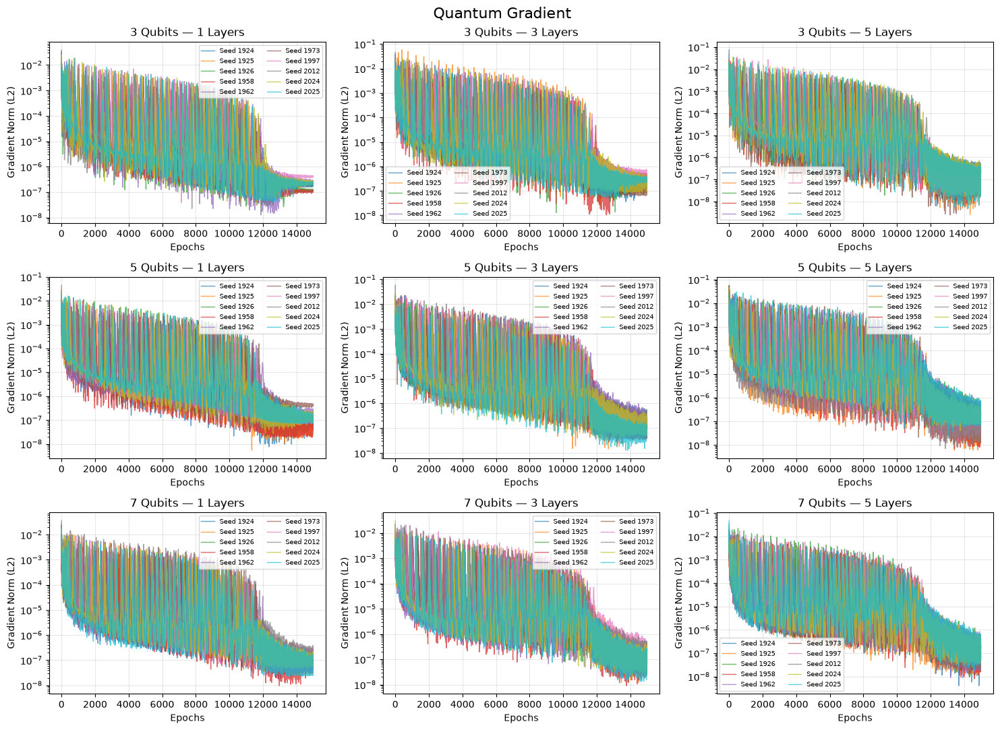

In [695]:
metricas = {
    "train_mse": "Training Loss",
    "grad_classical": "Classical Gradient",
    "grad_quantum": "Quantum Gradient"
}

for coluna, titulo in metricas.items():

    fig, axs = plt.subplots(3, 3, figsize=(15, 11))

    for i, q in enumerate(qubits_lista):
        for j, l in enumerate(camadas):
            ax = axs[i, j]
            dados = df[(df["qubits"] == q) & (df["layers"] == l)]

            for seed, grupo in dados.groupby("seed"):
                grupo = grupo.sort_values("epoch")

                ax.plot(
                    grupo["epoch"],
                    grupo[coluna].clip(lower=1e-12),
                    alpha=0.7,
                    linewidth=1,
                    label=f"Seed {seed}"
                )

            ax.set_title(f"{q} Qubits — {l} Layers")
            ax.set_xlabel("Epochs")
            ax.set_ylabel("MSE" if coluna == "train_mse" else "Gradient Norm (L2)")
            ax.grid(alpha=0.3)

            if not dados.empty:
                ax.set_yscale("log")
                ax.legend(fontsize=7, ncol=2)

    fig.suptitle(titulo, fontsize=16)
    plt.tight_layout()
    plt.show()

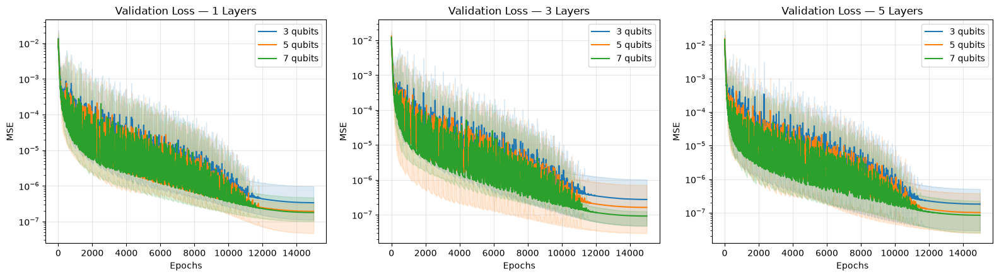

In [696]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, l in zip(axs, camadas):
    for q in qubits_lista:
        dados = df[(df["layers"] == l) & (df["qubits"] == q)]

        if dados.empty:
            continue

        resumo = dados.groupby("epoch")["val_mse"].agg(["mean", "min", "max"])

        ax.plot(resumo.index, resumo["mean"].clip(lower=1e-12),
                color=cores[q], label=f"{q} qubits")

        ax.fill_between(
            resumo.index,
            resumo["min"].clip(lower=1e-12),
            resumo["max"].clip(lower=1e-12),
            color=cores[q], alpha=0.15
        )

    ax.set_title(f"Validation Loss — {l} Layers")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.3)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

plt.tight_layout()
plt.show()

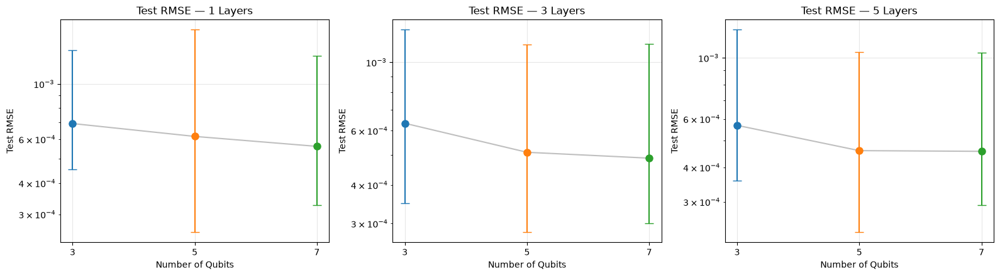

In [697]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, l in zip(axs, camadas):
    dados = resultados[resultados["layers"] == l]
    resumo = dados.groupby("qubits")["rmse"].agg(["mean", "min", "max"])

    for q, r in resumo.iterrows():
        ax.errorbar(
            q, r["mean"],
            yerr=[[r["mean"] - r["min"]], [r["max"] - r["mean"]]],
            fmt="o", color=cores[q], markersize=8, capsize=5
        )

    if not resumo.empty:
        ax.plot(resumo.index, resumo["mean"], color="gray", alpha=0.5)
        ax.set_yscale("log")

    ax.set_title(f"Test RMSE — {l} Layers")
    ax.set_xlabel("Number of Qubits")
    ax.set_ylabel("Test RMSE")
    ax.set_xticks(qubits_lista)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

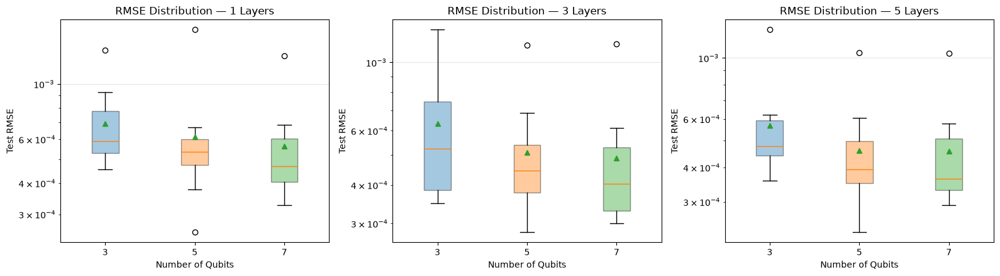

In [698]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, l in zip(axs, camadas):
    grupos = [
        resultados[
            (resultados["layers"] == l) &
            (resultados["qubits"] == q)
        ]["rmse"].dropna()
        for q in qubits_lista
    ]

    disponiveis = [
        (q, valores)
        for q, valores in zip(qubits_lista, grupos)
        if len(valores) > 0
    ]

    if disponiveis:
        bp = ax.boxplot(
            [v for q, v in disponiveis],
            tick_labels=[str(q) for q, v in disponiveis],
            patch_artist=True,
            showmeans=True
        )

        for patch, (q, _) in zip(bp["boxes"], disponiveis):
            patch.set_facecolor(cores[q])
            patch.set_alpha(0.4)

        ax.set_yscale("log")

    ax.set_title(f"RMSE Distribution — {l} Layers")
    ax.set_xlabel("Number of Qubits")
    ax.set_ylabel("Test RMSE")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

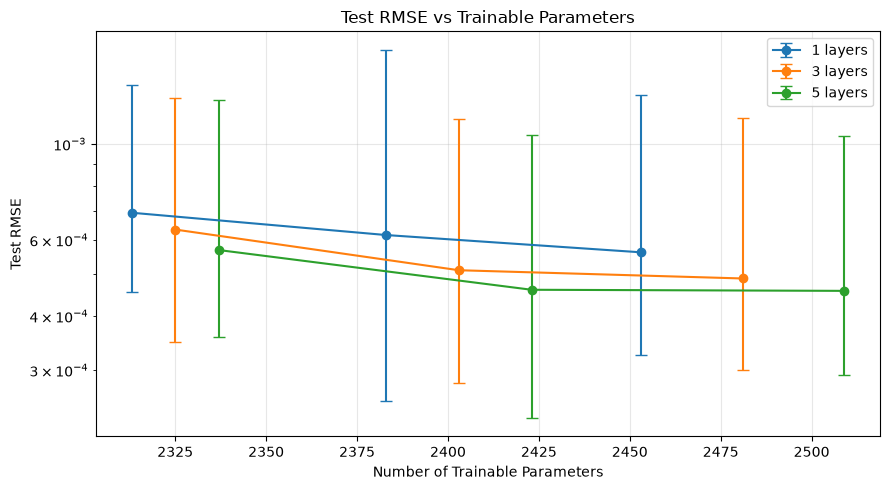

In [699]:
resumo = (
    resultados.groupby(["layers", "qubits"])
    .agg(
        parameters=("parameters", "first"),
        mean=("rmse", "mean"),
        min=("rmse", "min"),
        max=("rmse", "max")
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

for l in camadas:
    dados = resumo[resumo["layers"] == l].sort_values("parameters")

    if dados.empty:
        continue

    ax.errorbar(
        dados["parameters"],
        dados["mean"],
        yerr=[
            dados["mean"] - dados["min"],
            dados["max"] - dados["mean"]
        ],
        marker="o", capsize=4,
        label=f"{l} layers"
    )

ax.set_title("Test RMSE vs Trainable Parameters")
ax.set_xlabel("Number of Trainable Parameters")
ax.set_ylabel("Test RMSE")
ax.grid(alpha=0.3)

if ax.has_data():
    ax.set_yscale("log")
    ax.legend()

plt.tight_layout()
plt.show()

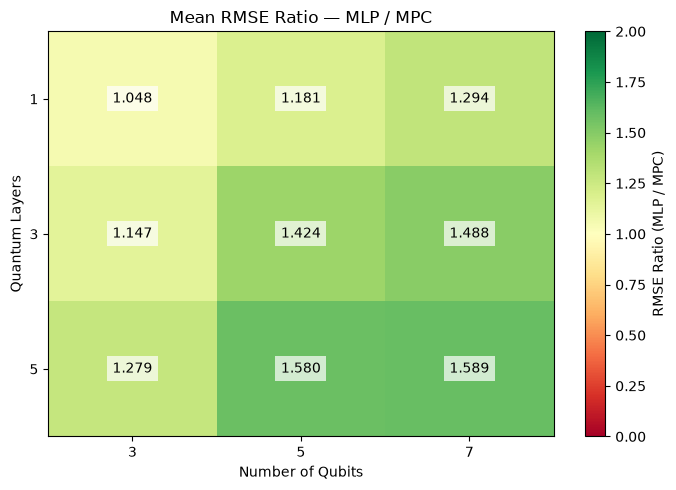

MLP Mean RMSE: 0.000727


In [700]:
# Carregar RMSE da MLP de referência
pasta_mlp = sorted(base.glob("mlp_points_[0-9]*"))[-1]
pasta_mlp = pasta_mlp / "results/burgers/mlp_points_1000"

rmse_mlp = [
    json.loads(p.read_text())["rmse"]
    for p in pasta_mlp.glob("seed_*/metrics.json")
]

media_mlp = sum(rmse_mlp) / len(rmse_mlp)

# RMSE médio da MPC
matriz_mpc = resultados.pivot_table(
    index="layers",
    columns="qubits",
    values="rmse",
    aggfunc="mean"
).reindex(index=camadas, columns=qubits_lista)

# Ratio MLP/MPC
ratio = media_mlp / matriz_mpc

fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(ratio.values, cmap="RdYlGn", aspect="auto", vmin=0, vmax=2)

ax.set_xticks(range(len(qubits_lista)), qubits_lista)
ax.set_yticks(range(len(camadas)), camadas)

ax.set_xlabel("Number of Qubits")
ax.set_ylabel("Quantum Layers")
ax.set_title("Mean RMSE Ratio — MLP / MPC")

for i in range(len(camadas)):
    for j in range(len(qubits_lista)):
        valor = ratio.iloc[i, j]

        if pd.notna(valor):
            ax.text(j, i, f"{valor:.3f}",
                    ha="center", va="center", color="black",
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))

fig.colorbar(im, ax=ax, label="RMSE Ratio (MLP / MPC)")

plt.tight_layout()
plt.show()

print(f"MLP Mean RMSE: {media_mlp:.6f}")

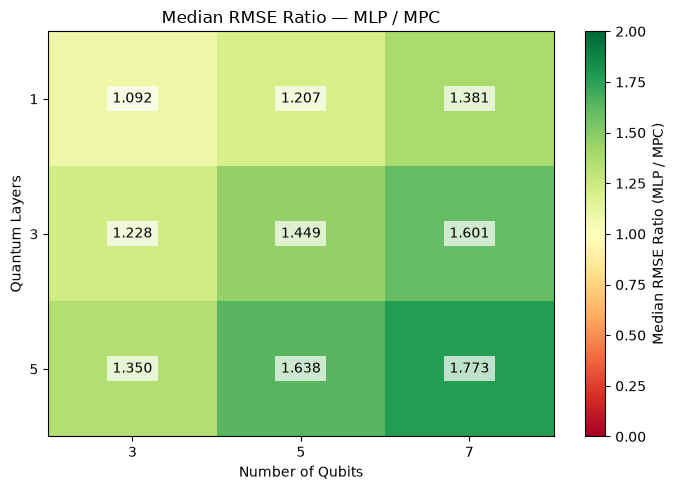

MLP Median RMSE: 0.000646


In [701]:
# RMSE mediano da MLP
mediana_mlp = np.median(rmse_mlp)

# RMSE mediano da MPC
matriz_mpc = resultados.pivot_table(
    index="layers",
    columns="qubits",
    values="rmse",
    aggfunc="median"
).reindex(index=camadas, columns=qubits_lista)

# Ratio das medianas
ratio = mediana_mlp / matriz_mpc

fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(ratio.values, cmap="RdYlGn", aspect="auto", vmin=0, vmax=2)

ax.set_xticks(range(len(qubits_lista)), qubits_lista)
ax.set_yticks(range(len(camadas)), camadas)

ax.set_xlabel("Number of Qubits")
ax.set_ylabel("Quantum Layers")
ax.set_title("Median RMSE Ratio — MLP / MPC")

for i in range(len(camadas)):
    for j in range(len(qubits_lista)):
        valor = ratio.iloc[i, j]

        if pd.notna(valor):
            ax.text(j, i, f"{valor:.3f}",
                    ha="center", va="center", color="black",
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))

fig.colorbar(im, ax=ax, label="Median RMSE Ratio (MLP / MPC)")

plt.tight_layout()
plt.show()

print(f"MLP Median RMSE: {mediana_mlp:.6f}")

In [702]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

base = Path("/home/camaral/inct_cq_hybrid_nn/runs")

pasta_quantum = base / "mpc_quantum_2527"
pasta_obs = sorted(base.glob("mpc_observables_[0-9]*"))[-1]
pasta_mlp = sorted(base.glob("mlp_points_[0-9]*"))[-1]

observaveis = ["Z", "ZZ", "XX", "YY", "Mixed"]

pastas = {
    "Z": pasta_quantum / "results/burgers/mpc_q5_l3",
    "ZZ": pasta_obs / "results/burgers/mpc_obs_zz",
    "XX": pasta_obs / "results/burgers/mpc_obs_xx",
    "YY": pasta_obs / "results/burgers/mpc_obs_yy",
    "Mixed": pasta_obs / "results/burgers/mpc_obs_mixed"
}

historicos = []
metricas = []

for obs, pasta in pastas.items():
    for arquivo in sorted(pasta.glob("seed_*/history.csv")):
        if arquivo.stat().st_size == 0:
            continue

        dados = pd.read_csv(arquivo)
        dados["observable"] = obs
        dados["seed"] = int(arquivo.parent.name.split("_")[-1])
        historicos.append(dados)

    for arquivo in sorted(pasta.glob("seed_*/metrics.json")):
        dados = json.loads(arquivo.read_text())
        dados["observable"] = obs
        dados["seed"] = int(arquivo.parent.name.split("_")[-1])
        metricas.append(dados)

df = pd.concat(historicos, ignore_index=True)
resultados = pd.DataFrame(metricas)

# Baseline MLP
arquivos_mlp = (
    pasta_mlp / "results/burgers/mlp_points_1000"
).glob("seed_*/metrics.json")

rmse_mlp = [json.loads(p.read_text())["rmse"] for p in arquivos_mlp]

cores = {
    "Z": "tab:blue",
    "ZZ": "tab:orange",
    "XX": "tab:green",
    "YY": "tab:red",
    "Mixed": "tab:purple"
}

print("Históricos:")
display(df.groupby("observable")["seed"].nunique())

print("Métricas finais:")
display(resultados.groupby("observable")["seed"].nunique())

Históricos:


observable
Mixed    10
XX       10
YY       10
Z        10
ZZ       10
Name: seed, dtype: int64

Métricas finais:


observable
Mixed    10
XX       10
YY       10
Z        10
ZZ       10
Name: seed, dtype: int64

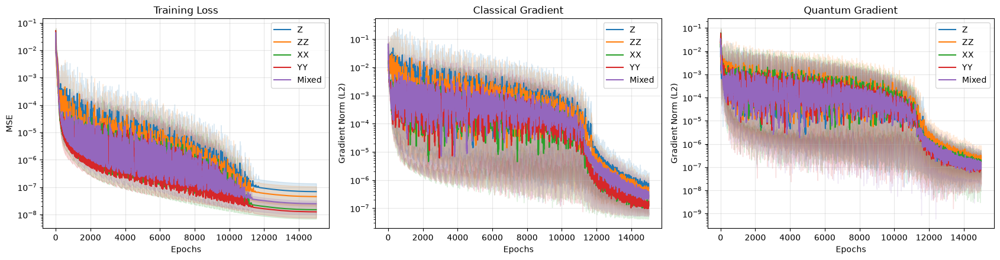

In [703]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))

colunas = ["train_mse", "grad_classical", "grad_quantum"]
titulos = ["Training Loss", "Classical Gradient", "Quantum Gradient"]

for obs in observaveis:
    dados = df[df["observable"] == obs]

    for ax, coluna in zip(axs, colunas):
        if dados.empty:
            continue

        resumo = dados.groupby("epoch")[coluna].agg(["mean", "min", "max"])

        ax.plot(resumo.index, resumo["mean"].clip(lower=1e-12),
                color=cores[obs], label=obs)

        ax.fill_between(
            resumo.index,
            resumo["min"].clip(lower=1e-12),
            resumo["max"].clip(lower=1e-12),
            color=cores[obs], alpha=0.15
        )

for ax, titulo in zip(axs, titulos):
    ax.set_title(titulo)
    ax.set_xlabel("Epochs")
    ax.grid(alpha=0.3)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

axs[0].set_ylabel("MSE")
axs[1].set_ylabel("Gradient Norm (L2)")
axs[2].set_ylabel("Gradient Norm (L2)")

plt.tight_layout()
plt.show()

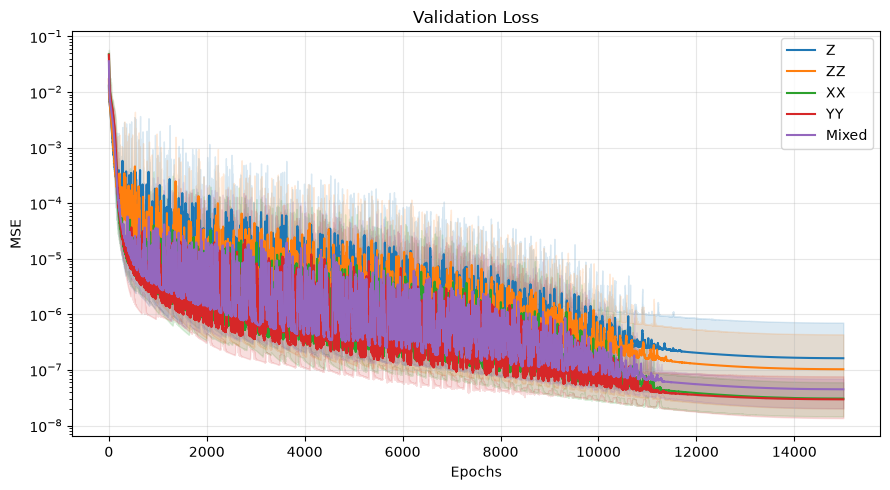

In [704]:
fig, ax = plt.subplots(figsize=(9, 5))

for obs in observaveis:
    dados = df[df["observable"] == obs]

    if dados.empty:
        continue

    resumo = dados.groupby("epoch")["val_mse"].agg(["mean", "min", "max"])

    ax.plot(resumo.index, resumo["mean"].clip(lower=1e-12),
            color=cores[obs], label=obs)

    ax.fill_between(
        resumo.index,
        resumo["min"].clip(lower=1e-12),
        resumo["max"].clip(lower=1e-12),
        color=cores[obs], alpha=0.15
    )

ax.set_title("Validation Loss")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.grid(alpha=0.3)

if ax.has_data():
    ax.set_yscale("log")
    ax.legend()

plt.tight_layout()
plt.show()

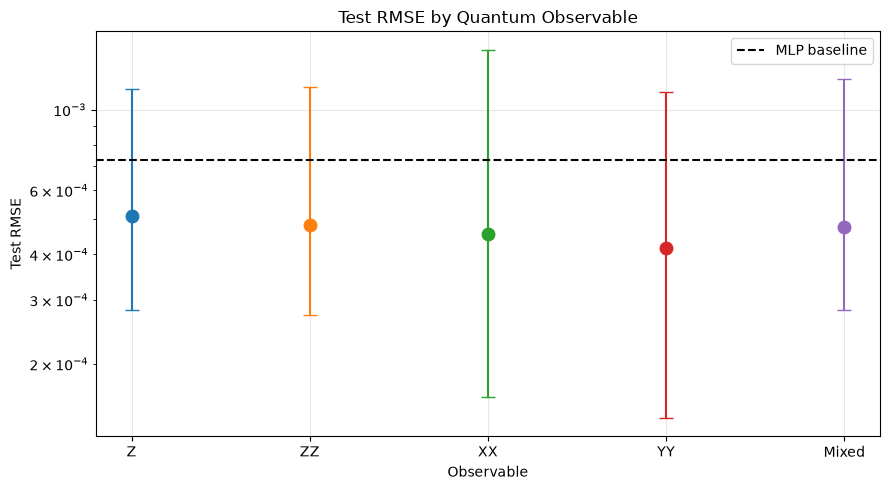

,mean,min,max,std
observable,,,,
Z,0.000511,0.000281,0.001139,0.000250
ZZ,0.000481,0.000272,0.001154,0.000262
XX,0.000454,0.000163,0.001461,0.000368
YY,0.000415,0.000142,0.001115,0.000270
Mixed,0.000477,0.000282,0.001210,0.000309


In [705]:
resumo = resultados.groupby("observable")["rmse"].agg(
    ["mean", "min", "max", "std"]
).reindex(observaveis).dropna(subset=["mean"])

fig, ax = plt.subplots(figsize=(9, 5))

for i, (obs, r) in enumerate(resumo.iterrows()):
    ax.errorbar(
        i, r["mean"],
        yerr=[[r["mean"] - r["min"]], [r["max"] - r["mean"]]],
        fmt="o", color=cores[obs], capsize=5, markersize=9
    )

ax.axhline(np.mean(rmse_mlp), color="black", linestyle="--",
           label="MLP baseline")

ax.set_xticks(range(len(resumo)), resumo.index)
ax.set_title("Test RMSE by Quantum Observable")
ax.set_xlabel("Observable")
ax.set_ylabel("Test RMSE")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

display(resumo.round(6))

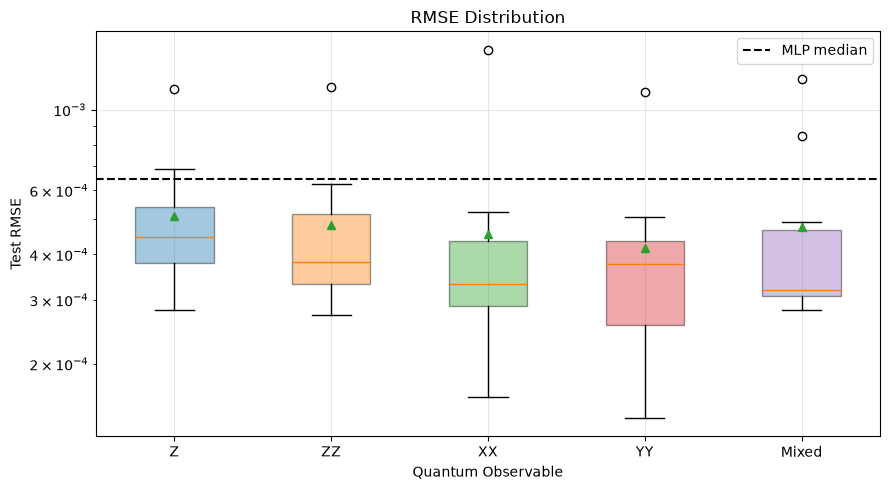

In [706]:
disponiveis = [
    obs for obs in observaveis
    if not resultados[resultados["observable"] == obs].empty
]

dados = [
    resultados[resultados["observable"] == obs]["rmse"].dropna()
    for obs in disponiveis
]

fig, ax = plt.subplots(figsize=(9, 5))

bp = ax.boxplot(
    dados,
    tick_labels=disponiveis,
    patch_artist=True,
    showmeans=True
)

for patch, obs in zip(bp["boxes"], disponiveis):
    patch.set_facecolor(cores[obs])
    patch.set_alpha(0.4)

ax.axhline(np.median(rmse_mlp), color="black", linestyle="--",
           label="MLP median")

ax.set_title("RMSE Distribution")
ax.set_xlabel("Quantum Observable")
ax.set_ylabel("Test RMSE")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

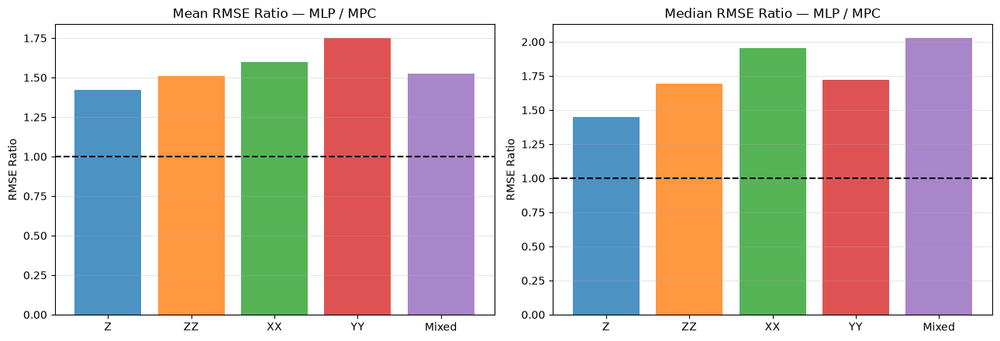

,mean,median,ratio_mean,ratio_median
observable,,,,
Z,0.00051,0.00045,1.42375,1.44942
ZZ,0.00048,0.00038,1.51042,1.69213
XX,0.00045,0.00033,1.60035,1.95280
YY,0.00042,0.00038,1.74984,1.72000
Mixed,0.00048,0.00032,1.52422,2.02738


In [707]:
estatisticas = resultados.groupby("observable")["rmse"].agg(
    ["mean", "median"]
).reindex(observaveis)

estatisticas["ratio_mean"] = np.mean(rmse_mlp) / estatisticas["mean"]
estatisticas["ratio_median"] = np.median(rmse_mlp) / estatisticas["median"]

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, coluna, titulo in zip(
    axs,
    ["ratio_mean", "ratio_median"],
    ["Mean RMSE Ratio — MLP / MPC", "Median RMSE Ratio — MLP / MPC"]
):
    for i, obs in enumerate(observaveis):
        valor = estatisticas.loc[obs, coluna]

        if pd.notna(valor):
            ax.bar(i, valor, color=cores[obs], alpha=0.8)

    ax.axhline(1, color="black", linestyle="--")
    ax.set_xticks(range(len(observaveis)), observaveis)
    ax.set_ylabel("RMSE Ratio")
    ax.set_title(titulo)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

display(estatisticas.round(5))

In [708]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = Path("/home/camaral/inct_cq_hybrid_nn/runs")

observaveis = ["Z", "ZZ", "XX", "YY", "Mixed"]
cores = dict(zip(observaveis, plt.cm.tab10.colors[:5]))

# Experimento polinomial
pasta_quantum = base / "mpc_quantum_2527"

pastas_poly = {
    "Z": pasta_quantum / "results/burgers/mpc_q5_l3"
}

pastas_obs = sorted(base.glob("mpc_observables_[0-9]*"))

if pastas_obs:
    pasta_obs = pastas_obs[-1]

    for obs in observaveis[1:]:
        pastas_poly[obs] = (
            pasta_obs
            / "results/burgers"
            / f"mpc_obs_{obs.lower()}"
        )

# Experimento com produtos cumulativos
pastas_product = sorted(
    base.glob("mpc_product_[0-9]*"),
    key=lambda p: int(p.name.rsplit("_", 1)[-1])
)

# Escolhe a execução mais recente que já tenha resultados
pastas_product = [
    p for p in pastas_product
    if list(p.rglob("history.csv")) or list(p.rglob("metrics.json"))
]

pasta_product = pastas_product[-1] if pastas_product else None

pastas = {}

for obs, pasta in pastas_poly.items():
    pastas[("Polinomial", obs)] = pasta

if pasta_product is not None:
    for obs in observaveis:
        pastas[("Produto", obs)] = (
            pasta_product
            / "results/burgers"
            / f"mpc_product_{obs.lower()}"
        )

historicos = []
metricas = []

for (metodo, obs), pasta in pastas.items():

    for arquivo in sorted(pasta.glob("seed_*/history.csv")):
        seed = int(arquivo.parent.name.split("_")[-1])
        temp = pd.read_csv(arquivo)

        temp["metodo"] = metodo
        temp["observable"] = obs
        temp["seed"] = seed

        historicos.append(temp)

    for arquivo in sorted(pasta.glob("seed_*/metrics.json")):
        seed = int(arquivo.parent.name.split("_")[-1])

        with open(arquivo) as f:
            m = json.load(f)

        metricas.append({
            "metodo": metodo,
            "observable": obs,
            "seed": seed,
            "rmse": m["rmse"],
            "mae": m.get("mae", np.nan),
            "relative_l2": m.get("relative_l2", np.nan),
            "parameters": m.get("parameters", np.nan),
        })

df = pd.concat(historicos, ignore_index=True) if historicos else pd.DataFrame()
resultados = pd.DataFrame(metricas)

# MLP de referência
pastas_mlp = sorted(
    base.glob("mlp_points_[0-9]*"),
    key=lambda p: int(p.name.rsplit("_", 1)[-1])
)

rmse_mlp = []

if pastas_mlp:
    for arquivo in pastas_mlp[-1].glob(
        "results/burgers/mlp_points_1000/seed_*/metrics.json"
    ):
        with open(arquivo) as f:
            rmse_mlp.append(json.load(f)["rmse"])

rmse_mlp = np.array(rmse_mlp)

print("Históricos:", len(historicos))
print("Métricas:", len(resultados))

if not resultados.empty:
    print(
        resultados.groupby(["metodo", "observable"])
        .agg(
            sementes=("seed", "nunique"),
            rmse_medio=("rmse", "mean")
        ).round(6)
    )

print("MLP:", len(rmse_mlp), "sementes")

Históricos: 100
Métricas: 100
                       sementes  rmse_medio
metodo     observable                      
Polinomial Mixed             10    0.000477
           XX                10    0.000454
           YY                10    0.000415
           Z                 10    0.000511
           ZZ                10    0.000481
Produto    Mixed             10    0.000477
           XX                10    0.000454
           YY                10    0.000415
           Z                 10    0.000511
           ZZ                10    0.000481
MLP: 10 sementes


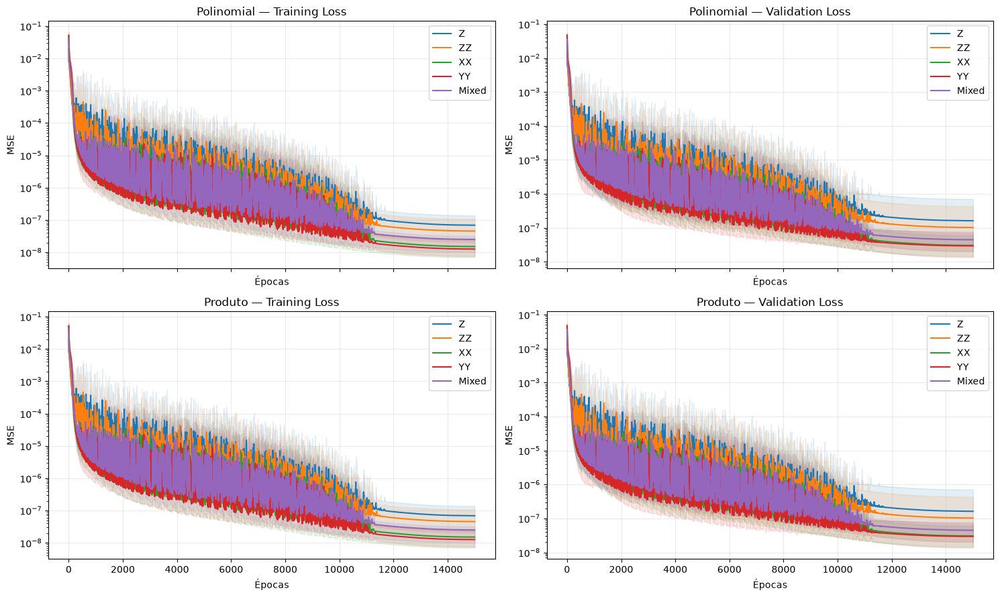

In [709]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)

for i, metodo in enumerate(["Polinomial", "Produto"]):
    for j, (coluna, titulo) in enumerate([
        ("train_mse", "Training Loss"),
        ("val_mse", "Validation Loss")
    ]):

        ax = axes[i, j]

        if not df.empty:
            for obs in observaveis:

                dados = df[
                    (df["metodo"] == metodo) &
                    (df["observable"] == obs)
                ]

                if dados.empty or coluna not in dados:
                    continue

                stats = dados.groupby("epoch")[coluna].agg(
                    ["mean", "min", "max"]
                )

                x = stats.index.to_numpy()
                media = stats["mean"].to_numpy()

                ax.plot(
                    x, np.maximum(media, 1e-15),
                    label=obs,
                    color=cores[obs]
                )

                ax.fill_between(
                    x,
                    np.maximum(stats["min"].to_numpy(), 1e-15),
                    np.maximum(stats["max"].to_numpy(), 1e-15),
                    color=cores[obs],
                    alpha=0.12
                )

        ax.set_title(f"{metodo} — {titulo}")
        ax.set_xlabel("Épocas")
        ax.set_ylabel("MSE")
        ax.grid(alpha=0.25)

        if ax.has_data():
            ax.set_yscale("log")
            ax.legend()

plt.tight_layout()
plt.show()

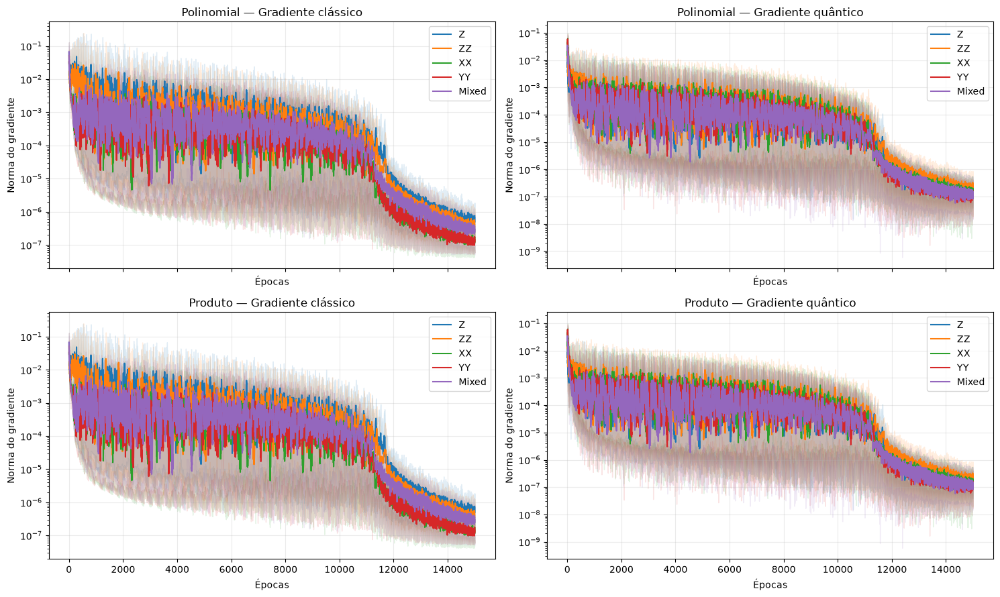

In [710]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)

for i, metodo in enumerate(["Polinomial", "Produto"]):

    for j, (coluna, titulo) in enumerate([
        ("grad_classical", "Gradiente clássico"),
        ("grad_quantum", "Gradiente quântico")
    ]):

        ax = axes[i, j]

        if not df.empty and coluna in df.columns:
            for obs in observaveis:

                dados = df[
                    (df["metodo"] == metodo) &
                    (df["observable"] == obs)
                ]

                if dados.empty:
                    continue

                stats = dados.groupby("epoch")[coluna].agg(
                    ["mean", "min", "max"]
                )

                x = stats.index.to_numpy()

                ax.plot(
                    x,
                    np.maximum(stats["mean"].to_numpy(), 1e-15),
                    label=obs,
                    color=cores[obs]
                )

                ax.fill_between(
                    x,
                    np.maximum(stats["min"].to_numpy(), 1e-15),
                    np.maximum(stats["max"].to_numpy(), 1e-15),
                    color=cores[obs],
                    alpha=0.12
                )

        ax.set_title(f"{metodo} — {titulo}")
        ax.set_xlabel("Épocas")
        ax.set_ylabel("Norma do gradiente")
        ax.grid(alpha=0.25)

        if ax.has_data():
            ax.set_yscale("log")
            ax.legend()

plt.tight_layout()
plt.show()

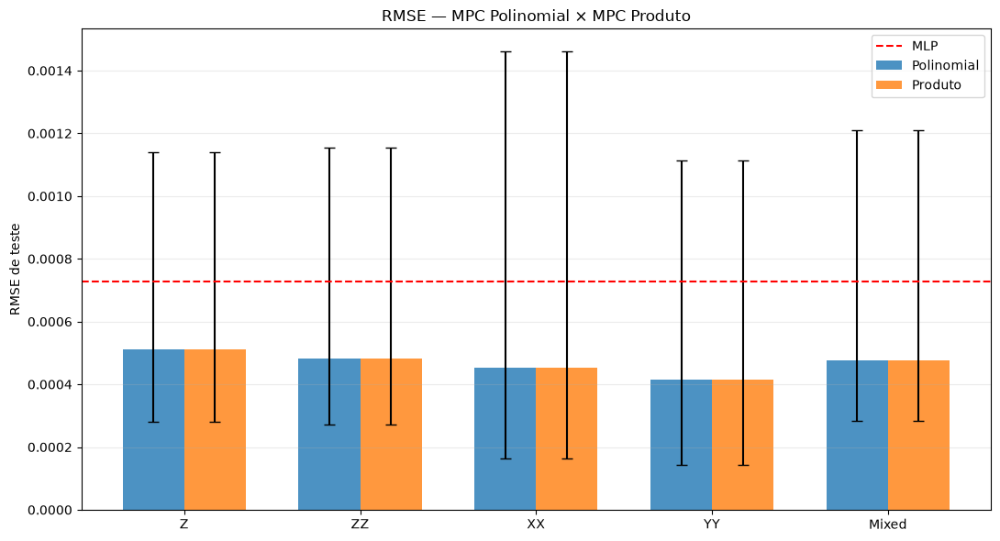

In [711]:
if not resultados.empty:

    fig, ax = plt.subplots(figsize=(11, 6))

    x = np.arange(len(observaveis))
    largura = 0.35

    for deslocamento, metodo, cor in [
        (-largura/2, "Polinomial", "tab:blue"),
        ( largura/2, "Produto", "tab:orange")
    ]:

        medias, mins, maxs = [], [], []

        for obs in observaveis:
            valores = resultados.loc[
                (resultados["metodo"] == metodo) &
                (resultados["observable"] == obs),
                "rmse"
            ].to_numpy()

            medias.append(valores.mean() if len(valores) else np.nan)
            mins.append(valores.min() if len(valores) else np.nan)
            maxs.append(valores.max() if len(valores) else np.nan)

        medias = np.array(medias)
        mins = np.array(mins)
        maxs = np.array(maxs)

        ax.bar(
            x + deslocamento,
            medias,
            width=largura,
            color=cor,
            alpha=0.8,
            label=metodo
        )

        validos = np.isfinite(medias)

        ax.errorbar(
            x[validos] + deslocamento,
            medias[validos],
            yerr=[
                medias[validos] - mins[validos],
                maxs[validos] - medias[validos]
            ],
            fmt="none",
            color="black",
            capsize=4
        )

    if len(rmse_mlp):
        ax.axhline(
            rmse_mlp.mean(),
            color="red",
            linestyle="--",
            label="MLP"
        )

    ax.set_xticks(x)
    ax.set_xticklabels(observaveis)
    ax.set_ylabel("RMSE de teste")
    ax.set_title("RMSE — MPC Polinomial × MPC Produto")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

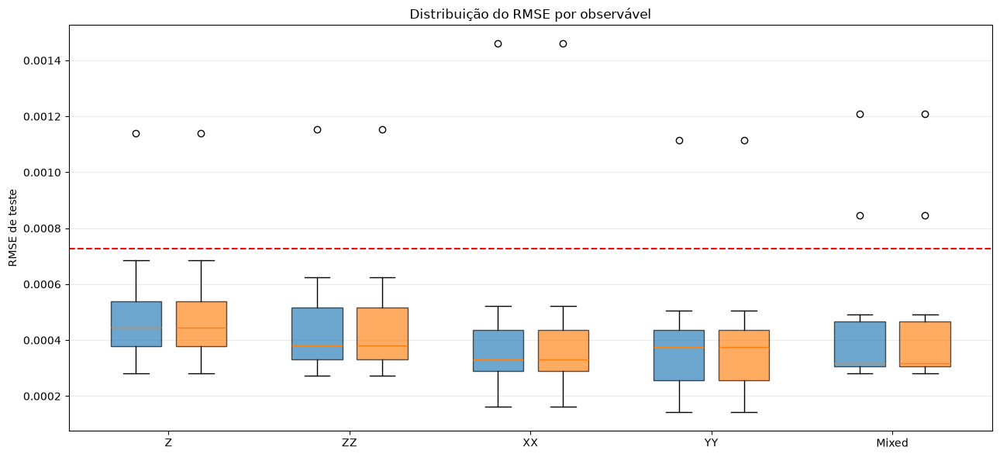

In [712]:
if not resultados.empty:

    fig, ax = plt.subplots(figsize=(13, 6))

    dados_box = []
    posicoes = []
    cores_box = []

    for i, obs in enumerate(observaveis):
        for deslocamento, metodo, cor in [
            (-0.18, "Polinomial", "tab:blue"),
            ( 0.18, "Produto", "tab:orange")
        ]:

            valores = resultados.loc[
                (resultados["metodo"] == metodo) &
                (resultados["observable"] == obs),
                "rmse"
            ].dropna().to_numpy()

            if len(valores):
                dados_box.append(valores)
                posicoes.append(i + deslocamento)
                cores_box.append(cor)

    if dados_box:
        bp = ax.boxplot(
            dados_box,
            positions=posicoes,
            widths=0.28,
            patch_artist=True,
            manage_ticks=False
        )

        for patch, cor in zip(bp["boxes"], cores_box):
            patch.set_facecolor(cor)
            patch.set_alpha(0.65)

    if len(rmse_mlp):
        ax.axhline(
            rmse_mlp.mean(),
            color="red",
            linestyle="--",
            label="MLP"
        )

    ax.set_xticks(range(len(observaveis)))
    ax.set_xticklabels(observaveis)
    ax.set_ylabel("RMSE de teste")
    ax.set_title("Distribuição do RMSE por observável")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

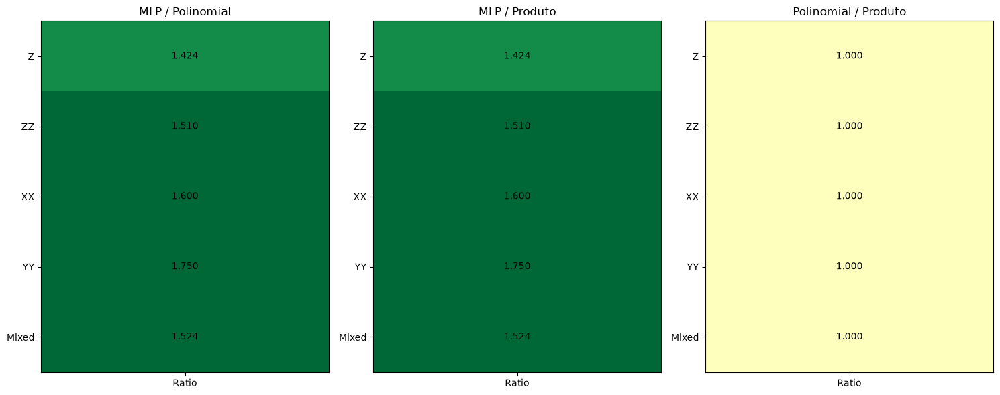

In [713]:
if not resultados.empty and len(rmse_mlp):

    tabela = resultados.pivot_table(
        index="observable",
        columns="metodo",
        values="rmse",
        aggfunc="mean"
    ).reindex(observaveis)

    comparacoes = []

    if "Polinomial" in tabela.columns:
        comparacoes.append((
            "MLP / Polinomial",
            rmse_mlp.mean() / tabela["Polinomial"]
        ))

    if "Produto" in tabela.columns:
        comparacoes.append((
            "MLP / Produto",
            rmse_mlp.mean() / tabela["Produto"]
        ))

    if {"Polinomial", "Produto"}.issubset(tabela.columns):
        comparacoes.append((
            "Polinomial / Produto",
            tabela["Polinomial"] / tabela["Produto"]
        ))

    fig, axes = plt.subplots(
        1, len(comparacoes),
        figsize=(5 * len(comparacoes), 6),
        squeeze=False
    )

    for ax, (titulo, valores) in zip(axes[0], comparacoes):

        matriz = valores.to_numpy().reshape(-1, 1)

        im = ax.imshow(
            matriz,
            cmap="RdYlGn",
            vmin=0.5,
            vmax=1.5,
            aspect="auto"
        )

        ax.set_yticks(range(len(observaveis)))
        ax.set_yticklabels(observaveis)
        ax.set_xticks([0])
        ax.set_xticklabels(["Ratio"])
        ax.set_title(titulo)

        for i, valor in enumerate(valores):
            if np.isfinite(valor):
                ax.text(
                    0, i, f"{valor:.3f}",
                    ha="center",
                    va="center",
                    color="black"
                )

    plt.tight_layout()
    plt.show()